# Arc artifact — statistical characterisation

**Question.** For the LSSTCam exposures flagged with the `arc` artifact, what
distinguishes them from everything else observed? Specifically:

1. **Pointing** — where was the telescope looking (alt/az, rotator, field)?
2. **Surroundings** — where were the Moon, the bright stars, the planets, relative
   to the boresight *and* relative to the camera?
3. **Telescope state** — dome azimuth, shutter, mirror covers, mount jitter,
   environment, image quality.

and is any of it *correlated with the arc appearing*, rather than merely
correlated with when we happened to point there?

## How this notebook is built

The naive comparison "arc exposures vs all exposures" is badly confounded. Three
traps, all real in this dataset, are handled explicitly:

| Trap | Why it bites | What we do |
|---|---|---|
| **Label epoch** | `arc` was not a label before 2025-07-11; ~90 nights of earlier data carry *no* arc flags by construction | restrict the control set to nights that were actually inspected |
| **Night clustering** | arcs arrive in bursts — 993 arcs on only 38 nights, in runs of consecutive exposures — so exposures are nowhere near independent | cluster-robust errors, night-stratified odds ratios, night fixed effects, and night-level cross-validation |
| **Observing strategy** | the survey points where the Moon *isn't*; anything the Moon drives will look like it also depends on alt/az/band | compare *within* night and *within* Moon-separation stratum |

The analysis therefore runs in layers, each narrower and more trustworthy than
the last:

- **§1–3** build the dataset (CSV labels + ConsDB + EFD + ephemeris).
- **§4** describes the arcs: when, how many, in what bursts.
- **§5** univariate screen — effect sizes, not just p-values.
- **§6** circular statistics for the angles (a position angle is not a number line).
- **§7** rate profiles and 2-D rate maps with confidence intervals.
- **§8** the confounder-controlled models: stratified ORs, night fixed effects.
- **§9** multivariate check with night-grouped cross-validation.
- **§10** conclusions, written against what actually survived §8.


---
## 1. Setup

`common/` holds the shared modules (`geom_utils`). Configuration for the whole
notebook lives in the `CFG` block — change the artifact there to re-run this
entire analysis on `banana`, `horseshoe`, … instead.


In [1]:
# --- project bootstrap ---
# common/ holds the shared modules; this notebook uses geom_utils only.
import sys, pathlib
_common = str(pathlib.Path.cwd().parent / "common")
if _common not in sys.path:
    sys.path.insert(0, _common)
# -------------------------


In [2]:
import os
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.stats import rayleightest
from astropy.time import Time
from scipy import stats

import geom_utils as gu

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# --------------------------------------------------------------------------
# CFG -- everything tunable about this analysis lives here.
# --------------------------------------------------------------------------
class CFG:
    CSV = "../data/raw/stray_light_20260506.csv"
    FIGDIR = pathlib.Path("../outputs/figures/arc_stats")
    TABDIR = pathlib.Path("../outputs/arc_stats")
    CACHE = pathlib.Path("../outputs/arc_stats/cache")

    ARTIFACT = "arc"            # which artifact to characterise
    ARTIFACT_BIT = 512          # its bit in the `flag` column (see §2 for the check)

    # Nights before the artifact first appears carry no label for it, so they
    # cannot serve as controls. Set to None to auto-detect from the data.
    EPOCH_START = None

    # A night with zero flags of *any* kind was probably never inspected.
    REQUIRE_INSPECTED_NIGHT = True

    CONSDB_URL = "https://usdf-rsp.slac.stanford.edu/consdb"
    EFD_NAME = "usdf_efd"
    EFD_BUCKET = "20s"          # server-side downsampling for EFD time series
    USE_EFD = True              # set False to skip the (slow-ish) EFD pull
    USE_CONSDB = True

    SEED = 42
    ENV_FILE = "../.env"        # fallback source for CONSDB_TOKEN

CFG.FIGDIR.mkdir(parents=True, exist_ok=True)
CFG.TABDIR.mkdir(parents=True, exist_ok=True)
CFG.CACHE.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(CFG.SEED)


def consdb_token():
    """CONSDB_TOKEN from the environment, falling back to parsing .env.

    VS Code injects .env automatically, but a bare `jupyter`/`nbconvert` kernel
    does not -- so read the file ourselves rather than failing on a KeyError.
    """
    tok = os.environ.get("CONSDB_TOKEN")
    if tok:
        return tok
    path = pathlib.Path(CFG.ENV_FILE)
    if path.exists():
        for line in path.read_text().splitlines():
            key, _, val = line.partition("=")
            if key.strip() == "CONSDB_TOKEN":
                tok = val.strip().strip("'\"")
                os.environ["CONSDB_TOKEN"] = tok
                return tok
    raise RuntimeError(
        f"CONSDB_TOKEN not in the environment and not found in {path}. "
        "Regenerate it with `python common/create_dot_env.py` (see README).")


print("artifact:", CFG.ARTIFACT, "| bit:", CFG.ARTIFACT_BIT)


artifact: arc | bit: 512


### Plot style

One consistent look for every figure: thin marks, hairline recessive grid, a
fixed categorical order (never cycled), one blue→dark hue for sequential
magnitude and a blue↔red diverging pair with a neutral grey midpoint for
signed quantities. `ARC_C` is the arc colour everywhere, `REF_C` the control.


In [3]:
# Validated categorical palette (fixed slot order -- never cycle these).
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
       "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
ARC_C, REF_C = PAL[1], PAL[0]            # arc = orange, control = blue
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURF = "#e1e0d9", "#fcfcfb"
SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#eef4fd", "#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])
DIV = mpl.colors.LinearSegmentedColormap.from_list(
    "div_br", ["#184f95", "#5598e7", "#cde2fb", "#f0efec", "#f6c3c3", "#e34948", "#a32424"])
SEQ.set_bad("#f0efec")
DIV.set_bad("#f0efec")

mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.titlepad": 10, "axes.labelsize": 10,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.direction": "out", "ytick.direction": "out",
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0, "lines.markersize": 5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})


def finish(fig, name, note=None):
    """Save a figure under FIGDIR and optionally stamp a caption under it."""
    if note:
        fig.text(0.0, -0.02, note, ha="left", va="top", fontsize=8.5, color=MUTED, wrap=True)
    path = CFG.FIGDIR / f"{name}.png"
    fig.savefig(path)
    return path


def save_table(df, name):
    path = CFG.TABDIR / f"{name}.csv"
    df.to_csv(path, index=True)
    return path


---
## 2. Labels: the artifact flag, and when it started being used

The CSV carries both a text `artifact` column (`"tape;arc"`, …) and an integer
bitmask `flag`. We use the bitmask — it is unambiguous — but first confirm the
bit actually corresponds to the artifact name, rather than trusting the constant
in `CFG`.


In [4]:
raw = pd.read_csv(CFG.CSV)
print("rows in CSV:", len(raw))

# Calibration frames can't show a sky artifact; drop them up front.
is_cal = raw["img_type"].astype(str).str.contains("dark|flat|bias", case=False, na=False)
df = raw[~is_cal].copy()
print(f"dropped {is_cal.sum()} dark/flat/bias -> {len(df)} on-sky exposures")

# --- verify the bit <-> name mapping instead of assuming it -----------------
single = df[df["artifact"].notna()]
bits = {}
for name, grp in single.groupby(single["artifact"].astype(str)):
    if ";" in name:
        continue
    vals = sorted(grp["flag"].astype(int).unique())
    bits[name] = vals
mapping = pd.DataFrame(
    [(k, v[0] if len(v) == 1 else v, len(single[single["artifact"] == k])) for k, v in bits.items()],
    columns=["artifact", "flag_bit", "n_exclusive"]).sort_values("flag_bit")
print(mapping.to_string(index=False))

found = mapping.loc[mapping["artifact"] == CFG.ARTIFACT, "flag_bit"]
assert len(found) == 1 and int(found.iloc[0]) == CFG.ARTIFACT_BIT, (
    f"CFG.ARTIFACT_BIT={CFG.ARTIFACT_BIT} does not match the data ({found.tolist()})")
print(f"\nOK: '{CFG.ARTIFACT}' == bit {CFG.ARTIFACT_BIT}")

df["arc"] = (df["flag"].astype(int) & CFG.ARTIFACT_BIT) > 0
df["any_flag"] = df["flag"].astype(int) > 0
print(f"{CFG.ARTIFACT} exposures (whole CSV): {df['arc'].sum()} / {len(df)}"
      f" = {df['arc'].mean()*100:.3f} %")


rows in CSV: 116337
dropped 1031 dark/flat/bias -> 115306 on-sky exposures
 artifact  flag_bit  n_exclusive
     tape         1         7726
     shoe         2          120
   pillow         4          263
   nibble        16          114
   banana        32          746
    ghoul        64          462
     moon       128           14
 airplane       256           62
      arc       512          938
  lighton      1024           20
   smudge      2048          206
horseshoe      4096          102

OK: 'arc' == bit 512
arc exposures (whole CSV): 993 / 115306 = 0.861 %


### 2.1 The label epoch

This is the single most important correction in the notebook. If `arc` only
started being recorded partway through the survey, every earlier exposure is a
**false control** — unflagged because nobody was looking for arcs, not because
no arc was there. Including them inflates every effect.


In [5]:
df["date"] = pd.to_datetime(df["day_obs"].astype(str), format="%Y%m%d")
per_night = df.groupby("day_obs").agg(
    n=("arc", "size"),
    n_arc=("arc", "sum"),
    frac_any_flag=("any_flag", "mean"),
)
per_night["inspected"] = per_night["frac_any_flag"] > 0

first_arc = int(df.loc[df["arc"], "day_obs"].min())
EPOCH = CFG.EPOCH_START if CFG.EPOCH_START is not None else first_arc
print(f"first {CFG.ARTIFACT} label: {first_arc}  ->  epoch starts {EPOCH}")

pre = per_night[per_night.index < EPOCH]
post = per_night[per_night.index >= EPOCH]
print(f"pre-epoch : {len(pre):3d} nights, {int(pre['n'].sum()):6d} exposures, "
      f"{int(pre['n_arc'].sum())} arcs  <- excluded as false controls")
print(f"post-epoch: {len(post):3d} nights, {int(post['n'].sum()):6d} exposures, "
      f"{int(post['n_arc'].sum())} arcs")
print(f"  of which never-inspected nights (no flag of any kind): "
      f"{int((~post['inspected']).sum())} nights / {int(post.loc[~post['inspected'], 'n'].sum())} exposures")


first arc label: 20250711  ->  epoch starts 20250711
pre-epoch :  66 nights,  26875 exposures, 0 arcs  <- excluded as false controls
post-epoch: 197 nights,  88431 exposures, 993 arcs
  of which never-inspected nights (no flag of any kind): 29 nights / 10816 exposures


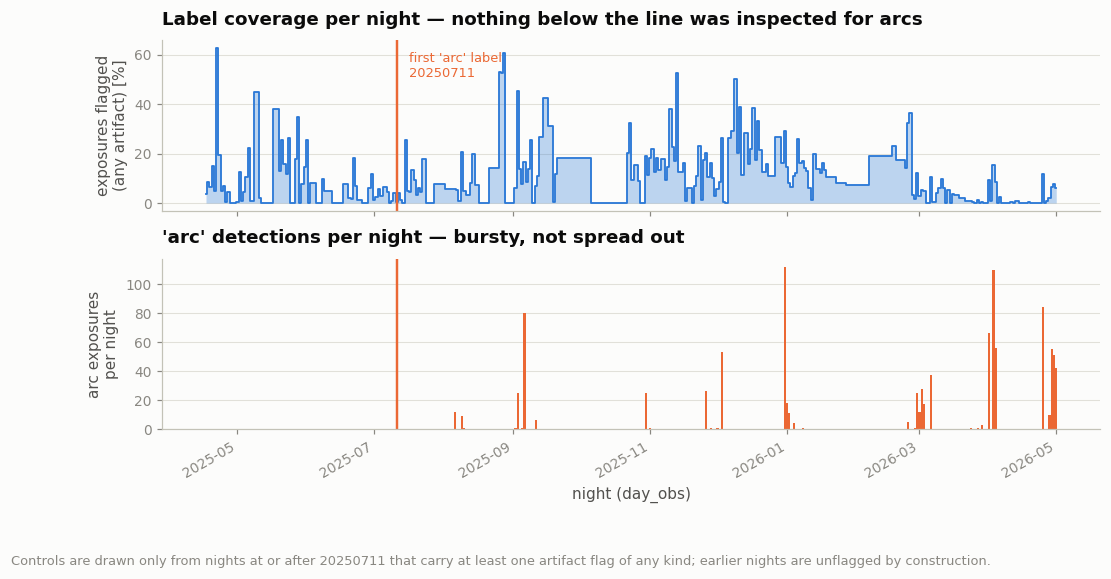

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1], "hspace": 0.28})
mdates = pd.to_datetime(per_night.index.astype(str), format="%Y%m%d")
epoch_dt = pd.to_datetime(str(EPOCH), format="%Y%m%d")

ax = axes[0]
ax.fill_between(mdates, 0, per_night["frac_any_flag"] * 100, step="mid",
                color=REF_C, alpha=0.30, linewidth=0)
ax.plot(mdates, per_night["frac_any_flag"] * 100, drawstyle="steps-mid",
        color=REF_C, linewidth=1.2)
ax.set_ylabel("exposures flagged\n(any artifact) [%]")
ax.set_title("Label coverage per night — nothing below the line was inspected for arcs")
ax.axvline(epoch_dt, color=ARC_C, linewidth=1.6)
ax.annotate(f"first '{CFG.ARTIFACT}' label\n{EPOCH}", (epoch_dt, ax.get_ylim()[1] * 0.93),
            xytext=(8, 0), textcoords="offset points", fontsize=8.5, color=ARC_C,
            va="top", ha="left")

ax = axes[1]
ax.bar(mdates, per_night["n_arc"], width=1.0, color=ARC_C, linewidth=0)
ax.set_ylabel(f"{CFG.ARTIFACT} exposures\nper night")
ax.set_xlabel("night (day_obs)")
ax.set_title(f"'{CFG.ARTIFACT}' detections per night — bursty, not spread out")
ax.axvline(epoch_dt, color=ARC_C, linewidth=1.6)
for a in axes:
    a.grid(axis="x", visible=False)
fig.autofmt_xdate()
finish(fig, "01_label_epoch",
       f"Controls are drawn only from nights at or after {EPOCH} that carry at least one "
       "artifact flag of any kind; earlier nights are unflagged by construction.")
plt.show()


### 2.2 The analysis frame

Two nested populations are used from here on:

- **`epoch`** — all on-sky exposures on inspected nights within the label epoch.
  This is the honest denominator for "how often does an arc happen".
- **`moon_up`** — the subset with the Moon above the horizon. §5 shows that
  essentially *every* arc lives here, so it is the right frame for asking what
  *modulates* the arc once the Moon is up.


In [7]:
sel = df["day_obs"] >= EPOCH
if CFG.REQUIRE_INSPECTED_NIGHT:
    inspected_nights = per_night.index[per_night["inspected"]]
    sel &= df["day_obs"].isin(inspected_nights)
epoch = df[sel].copy().reset_index(drop=True)

n_lost = int(df["arc"].sum() - epoch["arc"].sum())
print(f"analysis frame : {len(epoch)} exposures, {epoch['arc'].sum()} {CFG.ARTIFACT}, "
      f"{epoch['day_obs'].nunique()} nights")
print(f"base rate      : {epoch['arc'].mean()*100:.3f} %  "
      f"(vs {df['arc'].mean()*100:.3f} % against the uncorrected denominator)")
print(f"arcs excluded by the epoch/inspection cut: {n_lost}")


analysis frame : 77615 exposures, 993 arc, 168 nights
base rate      : 1.279 %  (vs 0.861 % against the uncorrected denominator)
arcs excluded by the epoch/inspection cut: 0


---
## 3. Enrichment — surroundings and telescope state

The CSV already carries the Moon and the two brightest field stars. We add:

| Source | What it adds |
|---|---|
| `geom_utils` + DE440s | planet positions (Venus/Jupiter/Saturn/Mars) and their angles |
| derived | Moon/star geometry **in the camera frame** — the frame a ghost actually lives in |
| ConsDB `visit1_quicklook` | delivered image quality, sky background, rotator |
| ConsDB `exposure_quicklook` | mount jitter and motion-induced degradation |
| EFD | dome azimuth, dome shutter, mirror covers at the exposure midpoint |

### 3.1 Derived geometry

A ghost or scattered-light arc is fixed in the **camera**, not on the sky. So
for every bright source we compute, besides the on-sky separation:

- `*_pa_cam` — position angle of the source **in the camera frame**,
  `pa_azalt − rotator_angle`, i.e. what the optics actually sees;
- `*_daz`, `*_dalt` — offset in the dome/structure frame, which is what matters
  for light bouncing off the dome, the mirror covers or the camera body.


In [8]:
def wrap180(x):
    """Wrap an angle difference into (-180, 180]."""
    return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0


def wrap360(x):
    return np.asarray(x, dtype=float) % 360.0


e = epoch

# --- Moon: sky, structure and camera frames --------------------------------
e["moon_daz"] = wrap180(e["moon_az"] - e["azimuth"])       # dome/structure frame
e["moon_dalt"] = e["moon_alt"] - e["altitude"]
e["moon_pa_cam"] = wrap360(e["moon_pa_azalt"] - e["rotator_angle"])
e["moon_pa_cam_radec"] = wrap360(e["moon_pa_radec"] - e["sky_rotation"])
e["moon_up"] = e["moon_alt"] > 0
# A crude but useful proxy for "how much Moon flux is around".
e["moon_bright"] = e["moon_illum"] * np.clip(np.sin(np.deg2rad(e["moon_alt"])), 0, None)

# --- brightest field stars -------------------------------------------------
for s in ("star0", "star1"):
    e[f"{s}_daz"] = wrap180(e[f"{s}_az"] - e["azimuth"])
    e[f"{s}_dalt"] = e[f"{s}_alt"] - e["altitude"]
    e[f"{s}_pa_cam"] = wrap360(e[f"{s}_pa_azalt"] - e["rotator_angle"])
    e[f"{s}_up"] = e[f"{s}_alt"] > 0

print("derived geometry columns added")
print(e[["moon_daz", "moon_dalt", "moon_pa_cam", "moon_bright"]].describe().round(3).to_string())


derived geometry columns added
        moon_daz  moon_dalt  moon_pa_cam  moon_bright
count  77615.000  77615.000    77615.000    77615.000
mean       8.521    -57.139      177.266        0.219
std      109.971     41.250      108.563        0.288
min     -179.999   -159.929        0.002        0.000
25%      -94.532    -90.474       74.141        0.000
50%       19.238    -56.318      182.010        0.012
75%      110.046    -26.345      274.074        0.433
max      179.999     60.822      359.986        0.984


### 3.2 Planets

Bright planets are the other plausible out-of-field source. `get_obj_position`
is vectorised over MJD, so the whole epoch costs a fraction of a second.


In [9]:
PLANETS = {"venus": "VENUS BARYCENTER", "jupiter": "JUPITER BARYCENTER",
           "saturn": "SATURN BARYCENTER", "mars": "MARS BARYCENTER"}

t_mid = Time(e["exp_midpt_mjd"].values, format="mjd", scale="utc")
boresight = SkyCoord(ra=e["ra"].values * u.deg, dec=e["dec"].values * u.deg, frame="icrs")

for short, body in PLANETS.items():
    pos = gu.get_obj_position(e["exp_midpt_mjd"].values, body)
    altaz = gu.convert_radec_to_altaz("rubin", t_mid, pos)
    e[f"{short}_sep"] = boresight.separation(pos).deg
    e[f"{short}_alt"] = altaz.alt.deg
    e[f"{short}_az"] = altaz.az.deg
    e[f"{short}_daz"] = wrap180(altaz.az.deg - e["azimuth"].values)
    e[f"{short}_up"] = e[f"{short}_alt"] > 0

print(e[[f"{p}_sep" for p in PLANETS]].describe().round(2).to_string())


       venus_sep  jupiter_sep  saturn_sep  mars_sep
count   77615.00     77615.00    77615.00  77615.00
mean      127.45        96.61       93.10    118.94
std        26.46        37.83       43.09     27.03
min        25.33         0.70        0.23      3.77
25%       109.18        69.03       58.71     98.48
50%       128.29        95.14       94.51    119.06
75%       148.11       125.39      127.60    139.03
max       179.72       179.39      179.66    179.76


### 3.3 ConsDB — telescope state and delivered image quality

`visit1_quicklook` carries the delivered image quality; `exposure_quicklook`
carries mount jitter. `can_see_sky` is the dome-occultation flag. Results are
cached to parquet so a re-run of the notebook does not re-query.


In [10]:
CONSDB_CACHE = CFG.CACHE / "consdb.parquet"

def fetch_consdb(day_min, day_max):
    from lsst.summit.utils import ConsDbClient
    client = ConsDbClient(CFG.CONSDB_URL, token=consdb_token())

    q_visit = f"""
        SELECT v.visit_id, v.can_see_sky, v.scheduler_note, v.pressure,
               vq.physical_rotator_angle, vq.sky_bg_median, vq.sky_noise_median,
               vq.psf_sigma_median, vq.zero_point_median, vq.eff_time_median,
               vq.seeing_zenith_500nm_median, vq.astrom_offset_mean_median,
               vq.aos_fwhm, vq.donut_blur_fwhm, vq.n_psf_star_median
        FROM cdb_lsstcam.visit1 AS v
        LEFT JOIN cdb_lsstcam.visit1_quicklook AS vq ON v.visit_id = vq.visit_id
        WHERE v.day_obs BETWEEN {day_min} AND {day_max}
    """
    q_exp = f"""
        SELECT exposure_id, mount_jitter_rms, mount_jitter_rms_az, mount_jitter_rms_el,
               mount_jitter_rms_rot, mount_motion_image_degradation,
               mount_jitter_rms_cam_hexapod, mount_jitter_rms_m2_hexapod
        FROM cdb_lsstcam.exposure_quicklook
        WHERE day_obs BETWEEN {day_min} AND {day_max}
    """
    vis = client.query(q_visit).to_pandas()
    exp = client.query(q_exp).to_pandas()

    vis["visit_id"] = vis["visit_id"].astype("int64")
    exp["exposure_id"] = exp["exposure_id"].astype("int64")
    num = [c for c in vis.columns if c not in ("visit_id", "can_see_sky", "scheduler_note")]
    vis[num] = vis[num].apply(pd.to_numeric, errors="coerce")
    num = [c for c in exp.columns if c != "exposure_id"]
    exp[num] = exp[num].apply(pd.to_numeric, errors="coerce")

    out = vis.merge(exp, left_on="visit_id", right_on="exposure_id", how="outer")
    out["visit_id"] = out["visit_id"].fillna(out["exposure_id"]).astype("int64")
    return out.drop(columns=["exposure_id"]).rename(columns={"visit_id": "exposure_id"})


if CFG.USE_CONSDB:
    if CONSDB_CACHE.exists():
        cdb = pd.read_parquet(CONSDB_CACHE)
        print(f"loaded ConsDB cache: {CONSDB_CACHE} ({len(cdb)} rows)")
    else:
        cdb = fetch_consdb(int(e["day_obs"].min()), int(e["day_obs"].max()))
        cdb.to_parquet(CONSDB_CACHE)
        print(f"fetched + cached {len(cdb)} ConsDB rows")

    e["exposure_id"] = e["exposure_id"].astype("int64")
    before = len(e)
    e = e.merge(cdb, on="exposure_id", how="left")
    assert len(e) == before, "ConsDB merge changed the row count"
    cov = e[["can_see_sky", "sky_bg_median", "mount_jitter_rms",
             "physical_rotator_angle"]].notna().mean()
    print("\njoin coverage:"); print(cov.round(3).to_string())
else:
    print("ConsDB skipped (CFG.USE_CONSDB = False)")


loaded ConsDB cache: ../outputs/arc_stats/cache/consdb.parquet (121353 rows)

join coverage:
can_see_sky               0.999
sky_bg_median             0.882
mount_jitter_rms          0.888
physical_rotator_angle    0.942


### 3.4 EFD — dome and mirror covers at the exposure midpoint

One InfluxQL query per topic per night, downsampled server-side to
`CFG.EFD_BUCKET`, then linearly interpolated onto each exposure midpoint. This
is ~1000× cheaper than the per-exposure `select_time_series` loop the previous
version of this notebook used, and it covers the whole epoch in about a minute.

Derived quantities that matter physically:

- `dome_tel_daz` — dome azimuth minus telescope azimuth: how far off-centre the
  telescope is looking through the slit;
- `dome_moon_daz` — dome azimuth minus Moon azimuth: whether the Moon is
  anywhere near the aperture.


In [11]:
EFD_CACHE = CFG.CACHE / f"efd_{CFG.EFD_BUCKET}.parquet"

# name -> (InfluxQL aggregate, topic)
EFD_TOPICS = {
    "dome_az":        ('mean("positionActual")',  "lsst.sal.MTDome.azimuth"),
    "dome_az_cmd":    ('mean("positionCommanded")', "lsst.sal.MTDome.azimuth"),
    "dome_shutter_a": ('mean("positionActual0")', "lsst.sal.MTDome.apertureShutter"),
    "dome_shutter_b": ('mean("positionActual1")', "lsst.sal.MTDome.apertureShutter"),
    "mirror_cover_0": ('mean("actualPosition0")', "lsst.sal.MTMount.mirrorCover"),
    "mirror_cover_1": ('mean("actualPosition1")', "lsst.sal.MTMount.mirrorCover"),
    "mirror_cover_2": ('mean("actualPosition2")', "lsst.sal.MTMount.mirrorCover"),
    "mirror_cover_3": ('mean("actualPosition3")', "lsst.sal.MTMount.mirrorCover"),
    "louver_max":     ('max("positionActual0")',  "lsst.sal.MTDome.louvers"),
}


async def fetch_efd(frame):
    """Per-night, server-side-downsampled EFD pull interpolated to exposure midpoints."""
    from lsst_efd_client import EfdClient
    client = EfdClient(CFG.EFD_NAME)

    by_topic = {}
    for name, (agg, topic) in EFD_TOPICS.items():
        by_topic.setdefault(topic, []).append((name, agg))

    nights = sorted(frame["day_obs"].unique())
    chunks = []
    for i, night in enumerate(nights):
        d0 = pd.to_datetime(str(night), format="%Y%m%d")
        # generous window: 16:00 on day_obs to 16:00 the next day, in UTC
        t0 = (d0 + pd.Timedelta(hours=16)).strftime("%Y-%m-%dT%H:%M:%SZ")
        t1 = (d0 + pd.Timedelta(hours=40)).strftime("%Y-%m-%dT%H:%M:%SZ")

        series = {}
        for topic, cols in by_topic.items():
            sel = ", ".join(f"{agg} AS {name}" for name, agg in cols)
            q = (f'SELECT {sel} FROM "efd"."autogen"."{topic}" '
                 f"WHERE time >= '{t0}' AND time <= '{t1}' "
                 f"GROUP BY time({CFG.EFD_BUCKET}) fill(none)")
            try:
                res = await client.influxql_query(q)
            except Exception as exc:                      # a topic can be absent for a night
                print(f"  [{night}] {topic}: {type(exc).__name__} {str(exc)[:70]}")
                continue
            if res is None or not len(res):
                continue
            for name, _ in cols:
                if name in res:
                    series[name] = pd.to_numeric(res[name], errors="coerce").dropna()

        g = frame[frame["day_obs"] == night]
        want = Time(g["exp_midpt_mjd"].values, format="mjd", scale="utc")
        want_ns = pd.DatetimeIndex(want.datetime, tz="UTC").values.astype("int64")
        rec = pd.DataFrame(index=g.index)
        for name, s in series.items():
            if len(s) < 2:
                continue
            rec[name] = np.interp(want_ns, s.index.values.astype("int64"),
                                  s.values.astype(float), left=np.nan, right=np.nan)
        chunks.append(rec)
        if i % 40 == 0:
            print(f"  EFD {i+1}/{len(nights)} nights ({night})")

    return pd.concat(chunks).reindex(frame.index)


if CFG.USE_EFD:
    if EFD_CACHE.exists():
        efd = pd.read_parquet(EFD_CACHE)
        efd.index = e.index[: len(efd)] if len(efd) == len(e) else efd.index
        print(f"loaded EFD cache: {EFD_CACHE} ({len(efd)} rows)")
    else:
        efd = await fetch_efd(e)                      # noqa: F704 (notebook top-level await)
        efd.to_parquet(EFD_CACHE)
        print(f"fetched + cached EFD for {len(efd)} exposures")
    e = e.join(efd)
    print("\nEFD coverage:")
    print(e[list(EFD_TOPICS)].notna().mean().round(3).to_string())
else:
    print("EFD skipped (CFG.USE_EFD = False)")


loaded EFD cache: ../outputs/arc_stats/cache/efd_20s.parquet (77615 rows)

EFD coverage:
dome_az           1.000
dome_az_cmd       1.000
dome_shutter_a    1.000
dome_shutter_b    1.000
mirror_cover_0    1.000
mirror_cover_1    1.000
mirror_cover_2    1.000
mirror_cover_3    1.000
louver_max        0.801


In [12]:
# --- derived telescope-state quantities ------------------------------------
if "dome_az" in e:
    e["dome_tel_daz"] = wrap180(e["dome_az"] - e["azimuth"])
    e["dome_tel_daz_abs"] = e["dome_tel_daz"].abs()
    e["dome_moon_daz"] = wrap180(e["dome_az"] - e["moon_az"])
    e["dome_moon_daz_abs"] = e["dome_moon_daz"].abs()
    e["dome_follow_err"] = wrap180(e["dome_az"] - e["dome_az_cmd"])
    cov_cols = [c for c in e.columns if c.startswith("mirror_cover_")]
    e["mirror_cover_max"] = e[cov_cols].max(axis=1)
    e["dome_shutter_min"] = e[["dome_shutter_a", "dome_shutter_b"]].min(axis=1)

    print("mirror covers: max position over the 4 leaves (0 = stowed/open)")
    print(e.groupby("arc")["mirror_cover_max"].describe()[["min", "50%", "max"]].round(2).to_string())
    print("\ndome shutter: min of the two leaves (100 = fully open)")
    print(e.groupby("arc")["dome_shutter_min"].describe()[["min", "50%", "max"]].round(2).to_string())
    print("\nlouvers: max opening seen on an arc night")
    print(e.groupby("arc")["louver_max"].max().to_string())

print(f"\nenriched frame: {e.shape[0]} exposures x {e.shape[1]} columns")
e.to_parquet(CFG.TABDIR / f"{CFG.ARTIFACT}_enriched.parquet")


mirror covers: max position over the 4 leaves (0 = stowed/open)
        min  50%     max
arc                     
False  1.79  1.9  136.00
True   1.79  1.9    1.98

dome shutter: min of the two leaves (100 = fully open)
          min    50%     max
arc                         
False -100.00  99.98  100.05
True    99.96  99.97  100.04

louvers: max opening seen on an arc night
arc
False    0.0
True     0.0

enriched frame: 77615 exposures x 161 columns


---
## 4. What the arcs look like as a population

Before any correlation: how are the 993 arc exposures distributed in time, and
how independent are they? This sets the *effective* sample size — and it is far
smaller than the raw count.


In [13]:
arc = e[e["arc"]]
nonarc = e[~e["arc"]]

# runs of consecutive exposure_ids within a night = one contiguous event
a_sorted = arc.sort_values("exposure_id")
gap = a_sorted["exposure_id"].astype("int64").diff().ne(1) | a_sorted["day_obs"].diff().ne(0)
a_sorted = a_sorted.assign(run_id=gap.cumsum())
runs = a_sorted.groupby("run_id").agg(night=("day_obs", "first"), n=("exposure_id", "size"))

print(f"{CFG.ARTIFACT} exposures        : {len(arc)}")
print(f"distinct nights           : {arc['day_obs'].nunique()}")
print(f"contiguous runs           : {len(runs)}")
print(f"median / max run length   : {runs['n'].median():.0f} / {runs['n'].max()}")
print(f"exposures on arc nights   : {e[e['day_obs'].isin(arc['day_obs'])].shape[0]}")
print()
print("arcs per night (top 10):")
print(arc["day_obs"].value_counts().head(10).to_string())
print()
print("--> the effective sample size is closer to the ~%d nights than to %d exposures."
      % (arc["day_obs"].nunique(), len(arc)))


arc exposures        : 993
distinct nights           : 38
contiguous runs           : 76
median / max run length   : 8 / 84
exposures on arc nights   : 20744

arcs per night (top 10):
day_obs
20251231    112
20260403    110
20260425     84
20250906     80
20260401     66
20260404     56
20260429     55
20251203     53
20260430     51
20260501     42

--> the effective sample size is closer to the ~38 nights than to 993 exposures.


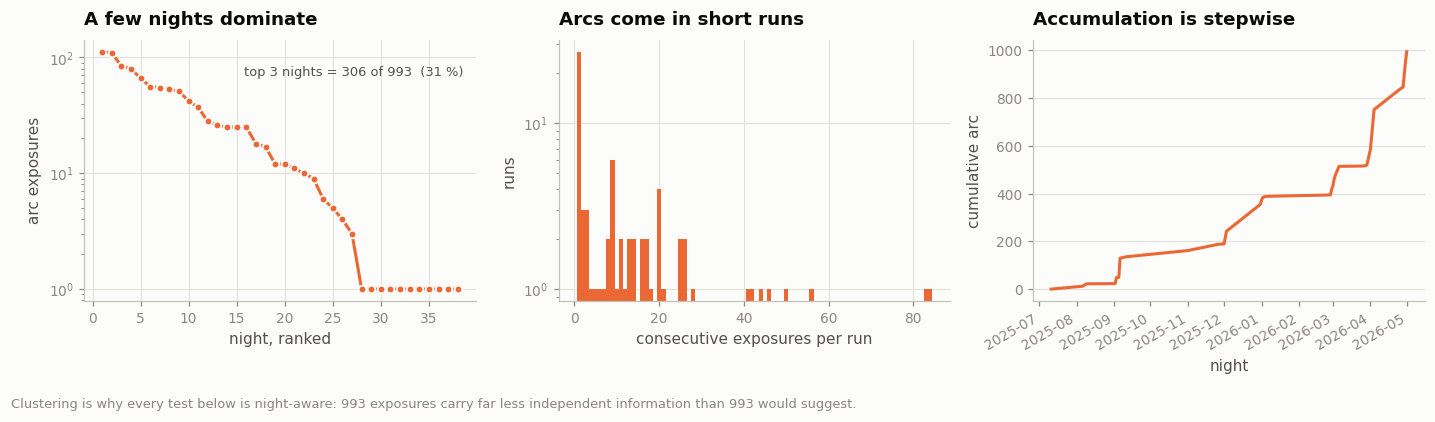

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

ax = axes[0]
counts = arc["day_obs"].value_counts().sort_values(ascending=False).values
ax.plot(np.arange(1, len(counts) + 1), counts, marker="o", color=ARC_C,
        markerfacecolor=ARC_C, markeredgecolor=SURF, markeredgewidth=1.2)
ax.set_yscale("log")
ax.set_xlabel("night, ranked")
ax.set_ylabel(f"{CFG.ARTIFACT} exposures")
ax.set_title("A few nights dominate")
top3 = counts[:3].sum()
# Annotate low-right, well clear of both the title and the curve.
ax.annotate(f"top 3 nights = {top3} of {len(arc)}  ({top3/len(arc)*100:.0f} %)",
            (0.97, 0.90), xycoords="axes fraction", ha="right", va="top",
            fontsize=8.5, color=INK2)

ax = axes[1]
bins = np.arange(0.5, runs["n"].max() + 1.5)
ax.hist(runs["n"], bins=bins, color=ARC_C, linewidth=0)
ax.set_yscale("log")
ax.set_xlabel("consecutive exposures per run")
ax.set_ylabel("runs")
ax.set_title("Arcs come in short runs")

ax = axes[2]
cum = arc.sort_values("day_obs").groupby("day_obs").size().cumsum()
ax.plot(pd.to_datetime(cum.index.astype(str), format="%Y%m%d"), cum.values, color=ARC_C)
ax.set_ylabel(f"cumulative {CFG.ARTIFACT}")
ax.set_xlabel("night")
ax.set_title("Accumulation is stepwise")
ax.grid(axis="x", visible=False)
for lab in ax.get_xticklabels():
    lab.set_rotation(30); lab.set_ha("right")

fig.tight_layout()
finish(fig, "02_population",
       "Clustering is why every test below is night-aware: 993 exposures carry far less "
       "independent information than 993 would suggest.")
plt.show()


---
## 5. Univariate screen

For every candidate quantity, we report an **effect size** — Cliff's δ, the
probability that a random arc exposure exceeds a random non-arc one, rescaled to
(−1, +1) — alongside the Mann–Whitney p-value. With n≈77 000 almost anything is
"significant", so δ is what we sort on.

The p-values here are *uncorrected for night clustering* and so are optimistic;
they serve to rank candidates, and §8 re-tests the survivors properly.


In [15]:
def cliffs_delta(a, b):
    """Cliff's delta and the Mann-Whitney p. delta>0 means `a` tends to exceed `b`."""
    a = np.asarray(a, dtype=float); a = a[np.isfinite(a)]
    b = np.asarray(b, dtype=float); b = b[np.isfinite(b)]
    if a.size < 5 or b.size < 5:
        return np.nan, np.nan, a.size, b.size
    uu, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return 2.0 * uu / (a.size * b.size) - 1.0, p, a.size, b.size


def screen(frame, cols, label=""):
    rows = []
    m = frame["arc"].values
    for c in cols:
        if c not in frame:
            continue
        d, p, na, nb = cliffs_delta(frame.loc[m, c], frame.loc[~m, c])
        rows.append({
            "variable": c, "cliffs_delta": d, "p": p,
            "median_arc": frame.loc[m, c].median(), "median_other": frame.loc[~m, c].median(),
            "n_arc": na, "n_other": nb,
        })
    out = pd.DataFrame(rows).dropna(subset=["cliffs_delta"])
    out["|delta|"] = out["cliffs_delta"].abs()
    # Benjamini-Hochberg across the screen
    order = np.argsort(out["p"].values)
    q = np.empty(len(out)); ranks = np.arange(1, len(out) + 1)
    q[order] = np.minimum.accumulate((out["p"].values[order] * len(out) / ranks)[::-1])[::-1]
    out["q_BH"] = np.clip(q, 0, 1)
    return out.sort_values("|delta|", ascending=False).reset_index(drop=True)


GROUPS = {
    "pointing": ["altitude", "azimuth", "zenith_distance", "airmass", "rotator_angle",
                 "sky_rotation", "parallactic_angle", "ra", "dec", "focus_z",
                 "physical_rotator_angle"],
    "moon": ["moon_sep", "moon_alt", "moon_illum", "moon_bright", "moon_daz", "moon_dalt",
             "moon_az"],
    "stars": ["star0_sep", "star0_vmag", "star0_alt", "star0_dalt", "star1_sep", "star1_vmag",
              "star1_alt", "star1_dalt"],
    "planets": [f"{p}_{k}" for p in PLANETS for k in ("sep", "alt")],
    "telescope": ["dome_tel_daz_abs", "dome_moon_daz_abs", "dome_follow_err",
                  "mirror_cover_max", "dome_shutter_min",
                  "mount_jitter_rms", "mount_jitter_rms_az", "mount_jitter_rms_el",
                  "mount_jitter_rms_rot", "mount_motion_image_degradation"],
    "environment": ["air_temp", "humidity", "wind_speed", "pressure", "dimm_seeing"],
    "image quality": ["sky_bg_median", "sky_noise_median", "psf_sigma_median",
                      "zero_point_median", "eff_time_median", "astrom_offset_mean_median",
                      "aos_fwhm", "donut_blur_fwhm", "n_psf_star_median"],
}
ALL_VARS = [c for g in GROUPS.values() for c in g]
VAR_GROUP = {c: g for g, cols in GROUPS.items() for c in cols}

scr_all = screen(e, ALL_VARS)
scr_all["group"] = scr_all["variable"].map(VAR_GROUP)
print("=== whole epoch (Moon up or down) ===")
print(scr_all.head(18)[["variable", "group", "cliffs_delta", "median_arc",
                        "median_other", "q_BH"]].to_string(index=False))
save_table(scr_all, f"{CFG.ARTIFACT}_screen_epoch")


=== whole epoch (Moon up or down) ===
        variable         group  cliffs_delta  median_arc  median_other          q_BH
        moon_sep          moon     -0.747419   43.364553     88.665442  0.000000e+00
     moon_bright          moon      0.737802    0.660821      0.007248  0.000000e+00
        moon_alt          moon      0.708976   45.946918      1.540204  0.000000e+00
      moon_illum          moon      0.645111    0.957480      0.537318 5.589308e-267
       moon_dalt          moon      0.611752  -19.286205    -57.217150 2.809628e-240
   sky_bg_median image quality      0.603357 4322.627686   2363.706299 1.219406e-184
sky_noise_median image quality      0.521836   66.231735     51.235451 1.814687e-138
        mars_alt       planets     -0.409821  -48.846223    -33.341206 1.420410e-108
 eff_time_median image quality     -0.282443    6.223809      9.131845  2.470877e-41
        air_temp   environment      0.276030   13.075000     11.475000  7.407091e-50
      star0_dalt         st

PosixPath('../outputs/arc_stats/arc_screen_epoch.csv')

### 5.1 The Moon gate

The first result dominates everything else, so it gets stated on its own.


In [16]:
up_arc = e.loc[e["arc"], "moon_up"].mean()
up_non = e.loc[~e["arc"], "moon_up"].mean()
n_dark_arc = int((~e.loc[e["arc"], "moon_up"]).sum())

tab = pd.crosstab(e["moon_up"], e["arc"])
odds, fisher_p = stats.fisher_exact(tab.values)
print(f"Moon above horizon:  {CFG.ARTIFACT} {up_arc*100:.2f} %   |   other {up_non*100:.2f} %")
print(f"{CFG.ARTIFACT} exposures with the Moon *below* the horizon: {n_dark_arc} / {len(arc)}")
print(f"\nFisher exact OR = {odds:.1f}  (p = {fisher_p:.2e})")
print("\nrate with the Moon up vs down:")
rate = e.groupby("moon_up")["arc"].agg(["size", "sum", "mean"])
rate["rate_%"] = rate["mean"] * 100
print(rate[["size", "sum", "rate_%"]].round(4).to_string())


Moon above horizon:  arc 99.09 %   |   other 51.13 %
arc exposures with the Moon *below* the horizon: 9 / 993

Fisher exact OR = 104.5  (p = 3.32e-266)

rate with the Moon up vs down:
          size  sum  rate_%
moon_up                    
False    37454    9  0.0240
True     40161  984  2.4501


In [17]:
moon_up = e[e["moon_up"]].copy()
print(f"Moon-up frame: {len(moon_up)} exposures, {moon_up['arc'].sum()} {CFG.ARTIFACT}, "
      f"rate {moon_up['arc'].mean()*100:.3f} %, {moon_up['day_obs'].nunique()} nights")

scr_up = screen(moon_up, ALL_VARS)
scr_up["group"] = scr_up["variable"].map(VAR_GROUP)
print("\n=== within the Moon-up frame (this is the honest screen) ===")
print(scr_up.head(22)[["variable", "group", "cliffs_delta", "median_arc",
                       "median_other", "q_BH"]].to_string(index=False))
save_table(scr_up, f"{CFG.ARTIFACT}_screen_moonup")


Moon-up frame: 40161 exposures, 984 arc, rate 2.450 %, 145 nights

=== within the Moon-up frame (this is the honest screen) ===
                 variable         group  cliffs_delta  median_arc  median_other          q_BH
                 moon_sep          moon     -0.543646   43.337442     67.260583 2.427217e-185
              moon_bright          moon      0.509540    0.662544      0.409163 3.737668e-163
                 moon_alt          moon      0.450921   46.039708     30.766003 4.513065e-128
                 mars_alt       planets     -0.379031  -49.067053    -34.059764  8.195473e-91
               moon_illum          moon      0.370780    0.957555      0.873791  4.949688e-87
                 mars_sep       planets      0.299725  131.874332    114.936760  3.146668e-57
                  airmass      pointing     -0.293772    1.065815      1.154150  4.454802e-55
                 altitude      pointing      0.292578   69.621776     59.988945  9.538257e-55
          zenith_distance 

PosixPath('../outputs/arc_stats/arc_screen_moonup.csv')

/lscratch/ataranto/ipykernel_3893367/518815759.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.975))


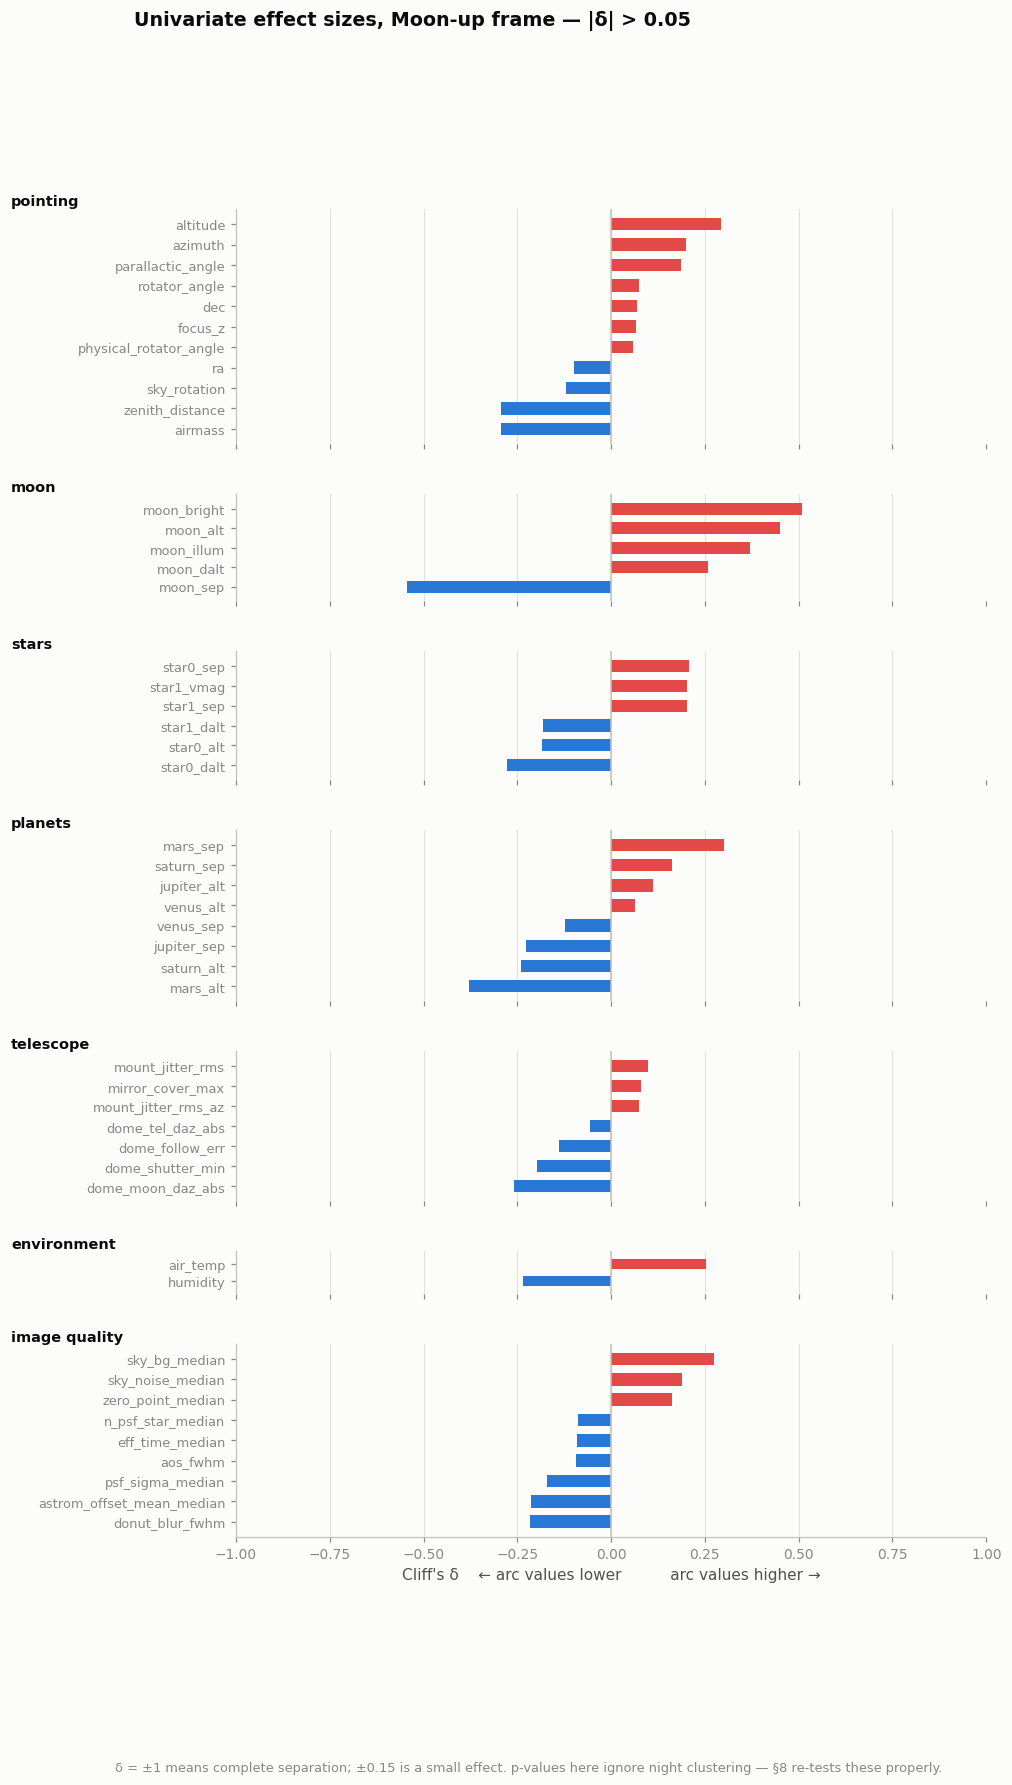

In [18]:
# Faceted by group, so group identity comes from position rather than from a
# seven-colour legend. Colour carries only the *sign* of the effect: the
# diverging blue<->red pair, which is what a signed quantity should use.
NEG_C, POS_C = "#2a78d6", "#e34948"

top = scr_up[scr_up["|delta|"] > 0.05].copy()
present = [g for g in GROUPS if g in set(top["group"])]
heights = [max(1, (top["group"] == g).sum()) for g in present]

# Row pitch is constant across facets, so bar thickness reads the same everywhere.
ROW = 0.235
fig_h = ROW * sum(heights) + 0.50 * len(present) + 0.9
fig, axes = plt.subplots(len(present), 1, figsize=(8.8, fig_h),
                         gridspec_kw={"height_ratios": heights, "hspace": 0.34})
axes = np.atleast_1d(axes)
for i, (ax, g) in enumerate(zip(axes, present)):
    sub = top[top["group"] == g].sort_values("cliffs_delta")
    y = np.arange(len(sub))
    ax.barh(y, sub["cliffs_delta"],
            color=[POS_C if v > 0 else NEG_C for v in sub["cliffs_delta"]],
            height=0.62, linewidth=0)
    ax.axvline(0, color="#c3c2b7", linewidth=1.0)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["variable"], fontsize=8.5)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-0.75, len(sub) - 0.25)
    ax.grid(axis="y", visible=False)
    # Group name in the left margin, so it never sits on a row label or a bar.
    ax.annotate(g, (-0.30, 1.0), xycoords="axes fraction", va="bottom", ha="left",
                fontsize=9.5, fontweight="semibold", color=INK)
    if i < len(present) - 1:
        ax.tick_params(labelbottom=False)
        ax.spines["bottom"].set_visible(False)
axes[-1].set_xlabel("Cliff's δ    ← arc values lower          arc values higher →")
fig.suptitle("Univariate effect sizes, Moon-up frame — |δ| > 0.05",
             x=0.02, y=0.995, ha="left", fontsize=12.5, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.975))
finish(fig, "03_effect_sizes",
       "δ = ±1 means complete separation; ±0.15 is a small effect. p-values here ignore "
       "night clustering — §8 re-tests these properly.")
plt.show()


---
## 6. The angles — circular statistics

`moon_pa_cam`, `rotator_angle`, `azimuth` and friends are **directions**. Mean
and standard deviation are meaningless on them (359° and 1° average to 180°),
and so is Cliff's δ. The right tools:

- **resultant length** R ∈ [0, 1] — 0 means uniform, 1 means all one direction;
- **Rayleigh test** — is the distribution non-uniform at all?
- **Watson's U²** with a permutation p-value — do arc and non-arc directions
  come from the same distribution? (Permutation, because the strata and ties
  here break the asymptotic table.)

If an arc is a **ghost fixed in the camera**, the tell-tale is a concentrated
`moon_pa_cam` — the Moon sitting at a preferred clock angle *in the camera*
whenever the arc shows up.


In [19]:
def circ_stats(deg):
    r = np.deg2rad(np.asarray(deg, dtype=float))
    r = r[np.isfinite(r)]
    if r.size == 0:
        return dict(R=np.nan, mean=np.nan, n=0, rayleigh_p=np.nan)
    C, S = np.cos(r).mean(), np.sin(r).mean()
    R = float(np.hypot(C, S))
    return dict(R=R, mean=float(np.rad2deg(np.arctan2(S, C)) % 360), n=int(r.size),
                rayleigh_p=float(rayleightest(r)))


def watson_u2(a, b):
    """Watson's two-sample U^2 statistic for circular samples (degrees)."""
    a = np.deg2rad(np.asarray(a, dtype=float)) % (2 * np.pi)
    b = np.deg2rad(np.asarray(b, dtype=float)) % (2 * np.pi)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    n, m = a.size, b.size
    if n < 3 or m < 3:
        return np.nan
    N = n + m
    pool = np.concatenate([a, b])
    order = np.argsort(pool, kind="mergesort")
    lab = np.concatenate([np.zeros(n), np.ones(m)])[order]
    d = np.cumsum(lab == 0) / n - np.cumsum(lab == 1) / m
    return float(n * m / N**2 * (np.sum(d**2) - np.sum(d) ** 2 / N))


def watson_perm_p(a, b, n_perm=1000, seed=CFG.SEED):
    """Permutation p for Watson U2 (the asymptotic table is invalid with heavy ties)."""
    a = np.asarray(a, float); a = a[np.isfinite(a)]
    b = np.asarray(b, float); b = b[np.isfinite(b)]
    obs = watson_u2(a, b)
    if not np.isfinite(obs):
        return obs, np.nan
    pool = np.concatenate([a, b]); n = a.size
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(n_perm):
        rng.shuffle(pool)
        if watson_u2(pool[:n], pool[n:]) >= obs:
            hits += 1
    return obs, (hits + 1) / (n_perm + 1)


ANGLES = ["moon_pa_cam", "moon_pa_cam_radec", "moon_pa_azalt", "moon_pa_radec",
          "moon_daz", "star1_pa_cam", "star0_pa_cam", "rotator_angle",
          "sky_rotation", "parallactic_angle", "azimuth", "dome_az"]

rows = []
for c in ANGLES:
    if c not in moon_up:
        continue
    sa = circ_stats(moon_up.loc[moon_up["arc"], c])
    sn = circ_stats(moon_up.loc[~moon_up["arc"], c])
    u2, pp = watson_perm_p(moon_up.loc[moon_up["arc"], c].dropna(),
                           moon_up.loc[~moon_up["arc"], c].dropna(), n_perm=600)
    rows.append({"angle": c, "R_arc": sa["R"], "mean_arc": sa["mean"],
                 "rayleigh_p_arc": sa["rayleigh_p"], "R_other": sn["R"],
                 "mean_other": sn["mean"], "watson_U2": u2, "perm_p": pp,
                 "R_excess": sa["R"] - sn["R"]})
circ = pd.DataFrame(rows).sort_values("R_excess", ascending=False)
print(circ.round(4).to_string(index=False))
save_table(circ, f"{CFG.ARTIFACT}_circular")

# Watson U2 here is an omnibus test with n=984 against n~40000: at that sample size
# it rejects "same distribution" for *every* angle, including rotator_angle, which
# is slightly *less* concentrated in arcs. If every perm_p equals the 1/(n_perm+1)
# floor, the column is saturated and cannot rank the angles -- say so rather than
# letting twelve identical p-values read as twelve independent detections.
_floor = 1.0 / (600 + 1)
if np.allclose(circ["perm_p"].dropna(), _floor):
    print(f"\nNOTE: every perm_p is at the permutation floor ({_floor:.2e}). Watson U2 "
          "is saturated at this sample size and carries no ranking information;\n"
          "      the angles are ordered by R_excess (effect size), and §6.2 "
          "calibrates that against a night-aware null.")


            angle  R_arc  mean_arc  rayleigh_p_arc  R_other  mean_other  watson_U2  perm_p  R_excess
    moon_pa_radec 0.5056   38.3341             0.0   0.2740     32.9226     4.1574  0.0017    0.2316
parallactic_angle 0.4251  125.2314             0.0   0.2130    126.0917     2.5750  0.0017    0.2121
     sky_rotation 0.3253   27.1855             0.0   0.1414     65.4351     3.2777  0.0017    0.1839
          azimuth 0.3554  285.3101             0.0   0.1770    254.1326     3.0945  0.0017    0.1784
          dome_az 0.3462  285.7824             0.0   0.1746    252.7040     2.8734  0.0017    0.1715
         moon_daz 0.4532   87.5969             0.0   0.3144    140.5239    11.1259  0.0017    0.1389
     star1_pa_cam 0.1625  245.2256             0.0   0.0391    299.9315     1.5713  0.0017    0.1233
     star0_pa_cam 0.2258  238.6014             0.0   0.1079    286.0233     2.2413  0.0017    0.1180
      moon_pa_cam 0.4400   43.6537             0.0   0.3801     18.7123     5.6663  0.0017 

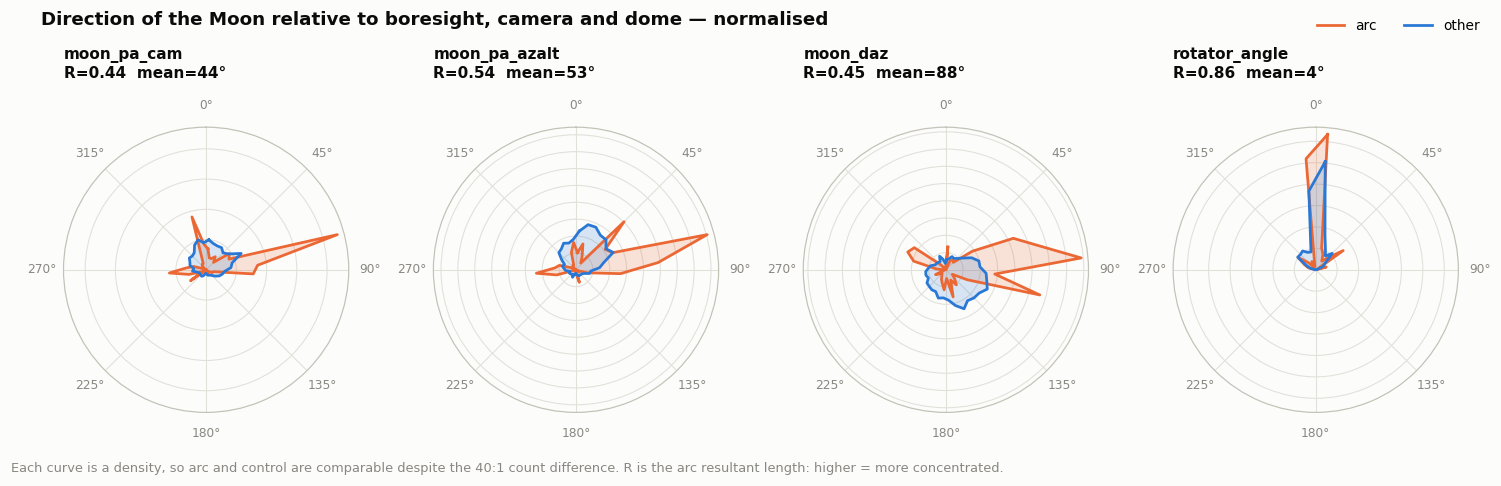

In [20]:
SHOW = [c for c in ["moon_pa_cam", "moon_pa_azalt", "moon_daz", "rotator_angle"]
        if c in moon_up]
fig, axes = plt.subplots(1, len(SHOW), figsize=(3.4 * len(SHOW), 4.1),
                         subplot_kw={"projection": "polar"})
axes = np.atleast_1d(axes)
nb = 36
edges = np.linspace(0, 2 * np.pi, nb + 1)
centres = (edges[:-1] + edges[1:]) / 2

for ax, c in zip(axes, SHOW):
    for mask, color, lab in ((moon_up["arc"], ARC_C, CFG.ARTIFACT),
                             (~moon_up["arc"], REF_C, "other")):
        v = np.deg2rad(moon_up.loc[mask, c].dropna().values % 360)
        h, _ = np.histogram(v, bins=edges)
        h = h / max(h.sum(), 1)                   # density, so the two are comparable
        ax.plot(np.r_[centres, centres[0]], np.r_[h, h[0]], color=color, linewidth=1.8,
                label=lab)
        ax.fill(np.r_[centres, centres[0]], np.r_[h, h[0]], color=color, alpha=0.18)
    s = circ_stats(moon_up.loc[moon_up["arc"], c])
    ax.set_title(f"{c}\nR={s['R']:.2f}  mean={s['mean']:.0f}°", fontsize=10, pad=14)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_yticklabels([])
    ax.grid(color=GRID, linewidth=0.7)
    ax.tick_params(labelsize=8, colors=MUTED)

# Figure-level legend in the header band, clear of both the dials and the caption.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.99, 0.99), ncol=2)
fig.suptitle("Direction of the Moon relative to boresight, camera and dome — normalised",
             x=0.02, ha="left", fontsize=12, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0.04, 1, 0.92))
finish(fig, "04_polar_angles",
       "Each curve is a density, so arc and control are comparable despite the 40:1 count "
       "difference. R is the arc resultant length: higher = more concentrated.")
plt.show()


### 6.2 Is that concentration real, or just the run structure?

`R_excess` above is not yet evidence. Arcs arrive in **contiguous runs** within a
handful of nights (§4), and every angle here drifts slowly and smoothly during a
night. So *any* contiguous block of exposures is concentrated in *any* of these
angles, whether or not it contains an arc. A high `R_arc` may say nothing beyond
"arcs come in runs".

The first fix is to compare the observed concentration against a null that at
least gets the *nights* right: keep each night's arc count, draw that many
exposures from that same night, and recompute. A z-score against that null is
interpretable where the raw `R_excess` is not.

Be clear about what this null does and does not absorb. It removes the
**between-night** confound — the fact that arc nights are a biased sample of
nights. It does **not** remove the run structure, because it draws scattered
exposures rather than a contiguous block, so a genuine run still beats it in every
frame at once. So read the z below as "more concentrated than a random draw from
the same nights", *not* as "fixed in this frame". §6.3 tightens the null to
contiguous blocks, and the conclusions there are the ones that bear weight.


In [21]:
def night_blocks(frame, col, kmin):
    """Per-night (values, arc mask, k) for nights with at least kmin arcs."""
    out = []
    for night, sub in frame.sort_values(["day_obs", "seq_num"]).groupby("day_obs"):
        k = int(sub["arc"].sum())
        v = sub[col].values.astype(float)
        if k >= kmin and np.isfinite(v).sum() >= k + 5:
            out.append((v, sub["arc"].values.astype(bool), k))
    return out


def circ_R(deg):
    r = np.deg2rad(np.asarray(deg, dtype=float))
    r = r[np.isfinite(r)]
    return float(np.hypot(np.cos(r).mean(), np.sin(r).mean())) if r.size > 1 else np.nan


def circ_mean(deg):
    r = np.deg2rad(np.asarray(deg, dtype=float))
    r = r[np.isfinite(r)]
    return float(np.rad2deg(np.arctan2(np.sin(r).mean(), np.cos(r).mean())) % 360) \
        if r.size else np.nan


def within_night_null_R(frame, col, n_perm=600, seed=CFG.SEED):
    """Observed pooled R for arcs vs a null drawing the same per-night counts."""
    blocks = night_blocks(frame, col, kmin=1)
    if not blocks:
        return np.nan, np.nan, np.nan, np.nan
    obs = circ_R(np.concatenate([v[y] for v, y, k in blocks]))
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        null[i] = circ_R(np.concatenate([
            v[rng.choice(np.where(np.isfinite(v))[0], k, replace=False)]
            for v, y, k in blocks]))
    mu, sd = null.mean(), null.std(ddof=1)
    z = (obs - mu) / sd if sd > 0 else np.nan
    return obs, mu, sd, z


rows = []
for c in ANGLES:
    if c not in moon_up:
        continue
    obs, mu, sd, z = within_night_null_R(moon_up, c, n_perm=400)
    rows.append({"angle": c, "R_arc": obs, "null_mean": mu, "null_sd": sd, "z": z})
circ_cal = pd.DataFrame(rows).sort_values("z", ascending=False)
print("Concentration of the arc sample, against a same-night same-count null:\n")
print(circ_cal.round(3).to_string(index=False))
save_table(circ_cal, f"{CFG.ARTIFACT}_circular_calibrated")
print("\nz is how many null SDs the arc concentration exceeds chance. Angles near "
      "z=0 are\nconcentrated only as much as any same-sized draw from the same "
      "nights already is.")


Concentration of the arc sample, against a same-night same-count null:

            angle  R_arc  null_mean  null_sd      z
    moon_pa_radec  0.506      0.291    0.011 19.062
         moon_daz  0.453      0.269    0.018 10.361
     star1_pa_cam  0.162      0.030    0.015  8.950
parallactic_angle  0.425      0.273    0.018  8.565
          azimuth  0.355      0.209    0.019  7.896
          dome_az  0.346      0.203    0.019  7.706
    moon_pa_azalt  0.544      0.459    0.014  5.890
      moon_pa_cam  0.440      0.359    0.015  5.419
moon_pa_cam_radec  0.443      0.362    0.015  5.396
     sky_rotation  0.325      0.230    0.019  5.114
    rotator_angle  0.859      0.857    0.005  0.313
     star0_pa_cam  0.226      0.225    0.019  0.065

z is how many null SDs the arc concentration exceeds chance. Angles near z=0 are
concentrated only as much as any same-sized draw from the same nights already is.


### 6.3 Which frame is the arc fixed in? — the telemetry-only test

This is the most useful question the telemetry can be pointed at, and the section
is equally about being precise where it stops being able to answer.

A stray-light feature is fixed in *some* frame, and each candidate implies a
different culprit:

| If the arc is fixed in… | then the Moon's direction should repeat in… | culprit |
|---|---|---|
| the **camera** | `moon_pa_cam` | optics, filter, L3 — a ghost |
| the **dome/structure** | `moon_daz` | dome slit, mirror covers, structure |
| the **sky** | `moon_pa_radec` | atmosphere, or an artefact of where we point |

The rotator is what makes this testable at all from telemetry: it is **decoupled**
from the parallactic angle in this dataset (r ≈ −0.08), so the camera, dome and sky
frames genuinely differ rather than being three names for one angle.

The test: if the arc is fixed in a frame, then the Moon's direction *in that
frame* should agree **across independent nights**. Per-night agreement is
worthless — a contiguous run is concentrated in every frame at once — so we take
one number per night (its mean arc direction) and measure agreement *between*
nights. The null draws a **contiguous block** of the same length from the same
night, which is the only null that reproduces the run structure instead of
breaking it.


In [22]:
FRAMES = [("moon_pa_cam", "camera", "optics / ghost"),
          ("moon_daz", "dome", "dome, covers, structure"),
          ("moon_pa_radec", "sky", "atmosphere / pointing"),
          ("moon_pa_azalt", "alt-az", "horizon-fixed")]
KMIN, NPERM = 8, 2000


def across_night_agreement(frame, col, label, kmin=KMIN, n_perm=NPERM, seed=CFG.SEED):
    """R between per-night mean arc directions, vs a contiguous-block null.

    The block null is the important part: arcs are runs, so a null that samples
    scattered exposures would be beaten by *any* run and would manufacture
    significance in every frame at once.
    """
    blocks = night_blocks(frame, col, kmin)
    if len(blocks) < 5:
        return None
    obs = circ_R([circ_mean(v[y]) for v, y, k in blocks])
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        dirs = []
        for v, y, k in blocks:
            start = rng.integers(0, max(1, len(v) - k + 1))
            dirs.append(circ_mean(v[start:start + k]))
        null[i] = circ_R(dirs)
    mu, sd = null.mean(), null.std(ddof=1)
    return {"frame": col, "label": label, "n_nights": len(blocks),
            "R_between": obs, "null_mean": mu, "null_sd": sd,
            "z": (obs - mu) / sd if sd > 0 else np.nan,
            "p": (np.sum(null >= obs) + 1) / (n_perm + 1)}


rows = []
for col, frame_label, culprit in FRAMES:
    if col not in moon_up:
        continue
    r = across_night_agreement(moon_up, col, frame_label)
    if r:
        r["implies"] = culprit
        rows.append(r)
frames_res = pd.DataFrame(rows).sort_values("z", ascending=False)
print(f"Across-night agreement of the mean arc direction  "
      f"(nights with >= {KMIN} arcs, contiguous-block null)\n")
print(frames_res[["frame", "label", "n_nights", "R_between", "null_mean",
                  "null_sd", "z", "p", "implies"]].round(3).to_string(index=False))
save_table(frames_res, f"{CFG.ARTIFACT}_frame_test")

# Bonferroni over the frames tested: this is a 4-way model-selection question,
# not four independent hypotheses.
n_tests = len(frames_res)
alpha = 0.05 / max(n_tests, 1)
win = frames_res[frames_res["p"] < alpha]
print(f"\nBonferroni threshold for {n_tests} frames: p < {alpha:.4f}")
if win.empty:
    best = frames_res.iloc[0]
    print(f"NO frame is identified. Best is '{best['label']}' "
          f"(z={best['z']:.2f}, p={best['p']:.3f}), which does not survive correction.")
    print("Telemetry alone cannot say which frame the arc is fixed in -- see §10.")
else:
    print(f"Identified frame: {win.iloc[0]['label']} -> {win.iloc[0]['implies']}")


Across-night agreement of the mean arc direction  (nights with >= 8 arcs, contiguous-block null)

        frame  label  n_nights  R_between  null_mean  null_sd     z     p                 implies
moon_pa_radec    sky        23      0.545      0.390    0.088 1.773 0.047   atmosphere / pointing
  moon_pa_cam camera        23      0.533      0.422    0.103 1.074 0.141          optics / ghost
     moon_daz   dome        23      0.451      0.359    0.106 0.864 0.203 dome, covers, structure
moon_pa_azalt alt-az        23      0.598      0.527    0.094 0.748 0.243           horizon-fixed

Bonferroni threshold for 4 frames: p < 0.0125
NO frame is identified. Best is 'sky' (z=1.77, p=0.047), which does not survive correction.
Telemetry alone cannot say which frame the arc is fixed in -- see §10.


In [23]:
# Sensitivity: the conclusion must not rest on one arbitrary arc-count threshold.
sens = []
for kmin in (4, 8, 15, 25):
    for col, frame_label, _ in FRAMES:
        if col not in moon_up:
            continue
        r = across_night_agreement(moon_up, col, frame_label, kmin=kmin, n_perm=800)
        if r:
            sens.append({"kmin": kmin, "frame": frame_label,
                         "n_nights": r["n_nights"], "z": r["z"], "p": r["p"]})
sens = pd.DataFrame(sens)
piv = sens.pivot(index="kmin", columns="frame", values="z").round(2)
print("z by minimum arcs-per-night (stability check):\n")
print(piv.to_string())
save_table(sens, f"{CFG.ARTIFACT}_frame_test_sensitivity")


z by minimum arcs-per-night (stability check):

frame  alt-az  camera  dome   sky
kmin                             
4        1.01    0.96  1.06  2.69
8        0.74    1.08  0.84  1.73
15      -0.04    0.52  0.32  1.78
25       0.28    0.18  1.01  1.35


PosixPath('../outputs/arc_stats/arc_frame_test_sensitivity.csv')

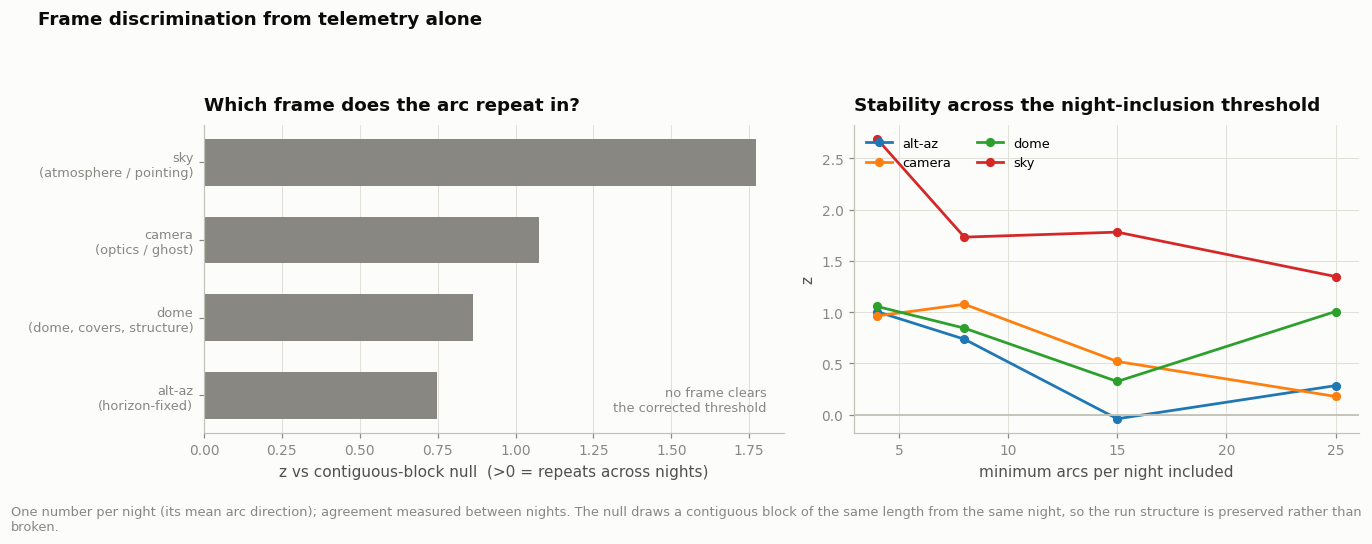

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.5),
                         gridspec_kw={"width_ratios": [1.15, 1]})

ax = axes[0]
f = frames_res.sort_values("z")
y = np.arange(len(f))
ax.barh(y, f["z"], color=np.where(f["p"] < alpha, ARC_C, MUTED), height=0.6, linewidth=0)
ax.axvline(0, color="#c3c2b7", linewidth=1.2)
ax.set_yticks(y)
ax.set_yticklabels([f"{l}\n({c})" for l, c in zip(f["label"], f["implies"])], fontsize=8.5)
ax.set_xlabel("z vs contiguous-block null  (>0 = repeats across nights)")
ax.set_title("Which frame does the arc repeat in?")
ax.grid(axis="y", visible=False)
ax.annotate("no frame clears\nthe corrected threshold" if win.empty else "identified",
            (0.97, 0.06), xycoords="axes fraction", ha="right", va="bottom",
            fontsize=8.5, color=MUTED)

ax = axes[1]
for frame_label, grp in sens.groupby("frame"):
    grp = grp.sort_values("kmin")
    ax.plot(grp["kmin"], grp["z"], marker="o", label=frame_label, linewidth=1.8)
ax.axhline(0, color="#c3c2b7", linewidth=1.2)
ax.set_xlabel("minimum arcs per night included")
ax.set_ylabel("z")
ax.set_title("Stability across the night-inclusion threshold")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 1.0), ncol=2, fontsize=8.5)

fig.suptitle("Frame discrimination from telemetry alone",
             x=0.02, ha="left", fontsize=12, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.91))
finish(fig, "12_frame_test",
       "One number per night (its mean arc direction); agreement measured between nights. "
       "The null draws a contiguous block of the same length from the same night, so the "
       "run structure is preserved rather than broken.")
plt.show()


---
## 7. Rate profiles

The screen above compares *distributions*. What an observer actually wants is
the **rate**: given that I am 40° from the Moon, how often do I get an arc?
Every bin carries a Wilson 95 % interval, and bins with fewer than 30 exposures
are dropped rather than plotted as noise.


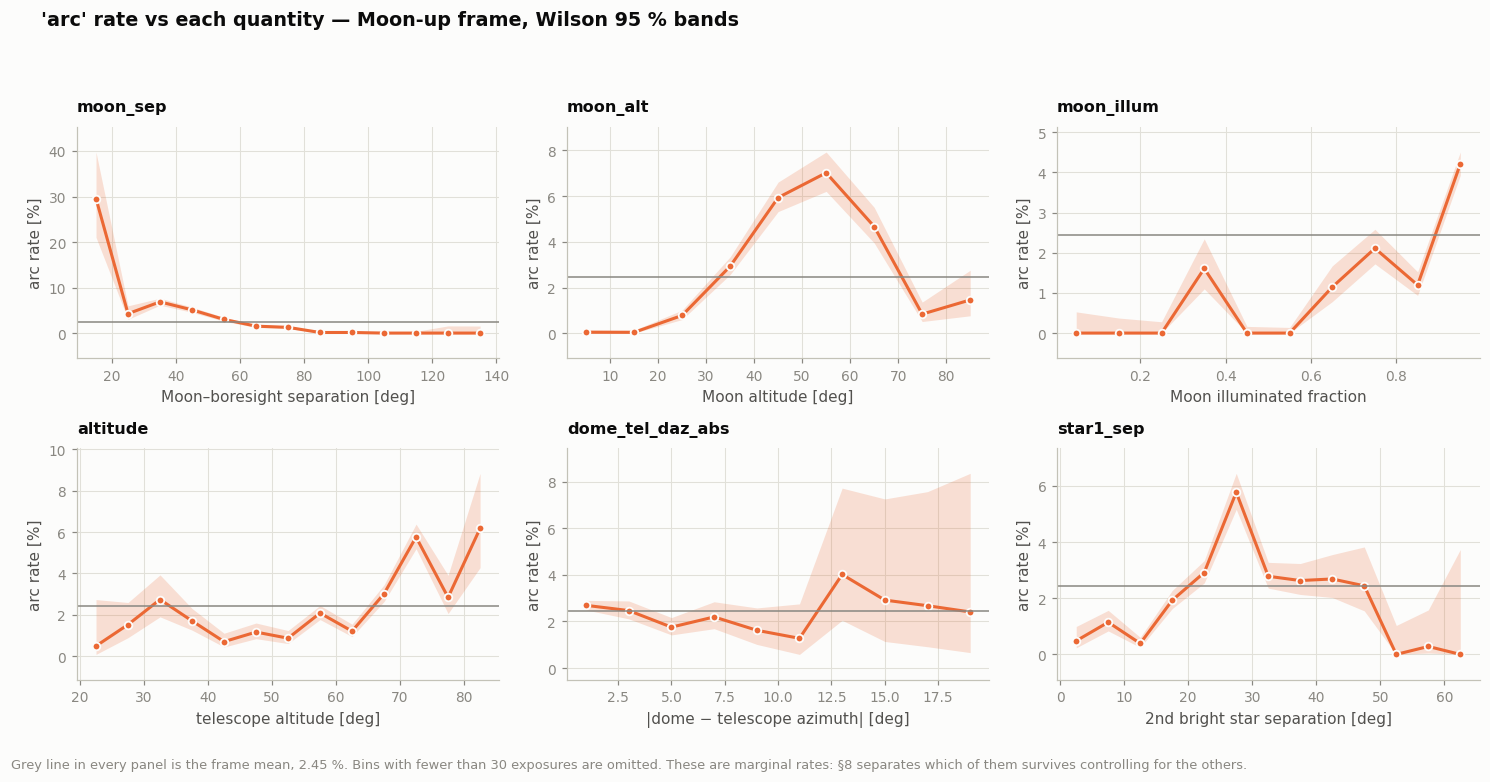

In [25]:
def wilson(k, n, z=1.959963984540054):
    k = np.asarray(k, dtype=float); n = np.asarray(n, dtype=float)
    p = np.divide(k, n, out=np.full_like(n, np.nan), where=n > 0)
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def rate_profile(frame, col, bins, min_n=30):
    g = frame.assign(_b=pd.cut(frame[col], bins)).groupby("_b", observed=True)["arc"]
    out = g.agg(n="size", k="sum")
    out = out[out["n"] >= min_n]
    p, lo, hi = wilson(out["k"], out["n"])
    out["rate"], out["lo"], out["hi"] = p * 100, lo * 100, hi * 100
    out["centre"] = [iv.mid for iv in out.index]
    return out


def plot_rate(ax, prof, xlabel, baseline=None, color=ARC_C, label_baseline=False):
    ax.fill_between(prof["centre"], prof["lo"], prof["hi"], color=color, alpha=0.20,
                    linewidth=0)
    ax.plot(prof["centre"], prof["rate"], color=color, marker="o",
            markerfacecolor=color, markeredgecolor=SURF, markeredgewidth=1.2)
    if baseline is not None:
        ax.axhline(baseline, color=MUTED, linewidth=1.0)
        # Label it once for the whole figure rather than over every curve.
        if label_baseline:
            ax.annotate(f"frame mean {baseline:.2f} %", (0.5, baseline),
                        xytext=(0, 5), textcoords="offset points", ha="center",
                        fontsize=8, color=MUTED)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"{CFG.ARTIFACT} rate [%]")
    return ax


base = moon_up["arc"].mean() * 100
SPECS = [
    ("moon_sep", np.arange(0, 185, 10), "Moon–boresight separation [deg]"),
    ("moon_alt", np.arange(0, 95, 10), "Moon altitude [deg]"),
    ("moon_illum", np.linspace(0, 1, 11), "Moon illuminated fraction"),
    ("altitude", np.arange(20, 95, 5), "telescope altitude [deg]"),
    ("dome_tel_daz_abs", np.arange(0, 22, 2), "|dome − telescope azimuth| [deg]"),
    ("star1_sep", np.arange(0, 70, 5), "2nd bright star separation [deg]"),
]
SPECS = [s for s in SPECS if s[0] in moon_up]

fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.8))
for i, (ax, (col, bins, xlabel)) in enumerate(zip(axes.ravel(), SPECS)):
    prof = rate_profile(moon_up, col, bins)
    plot_rate(ax, prof, xlabel, baseline=base, label_baseline=(i == 0))
    ax.set_title(col, fontsize=10.5)
    ax.margins(y=0.14)
for ax in axes.ravel()[len(SPECS):]:
    ax.remove()
fig.suptitle(f"'{CFG.ARTIFACT}' rate vs each quantity — Moon-up frame, Wilson 95 % bands",
             x=0.02, ha="left", fontsize=12.5, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
finish(fig, "05_rate_profiles",
       f"Grey line in every panel is the frame mean, {base:.2f} %. Bins with fewer than 30 "
       "exposures are omitted. These are marginal rates: §8 separates which of them "
       "survives controlling for the others.")
plt.show()


### 7.1 Two dimensions at a time

A marginal profile cannot tell whether Moon separation and Moon brightness are
two effects or one. A 2-D rate map can. Cells with fewer than 25 exposures are
left blank rather than coloured from a handful of frames.


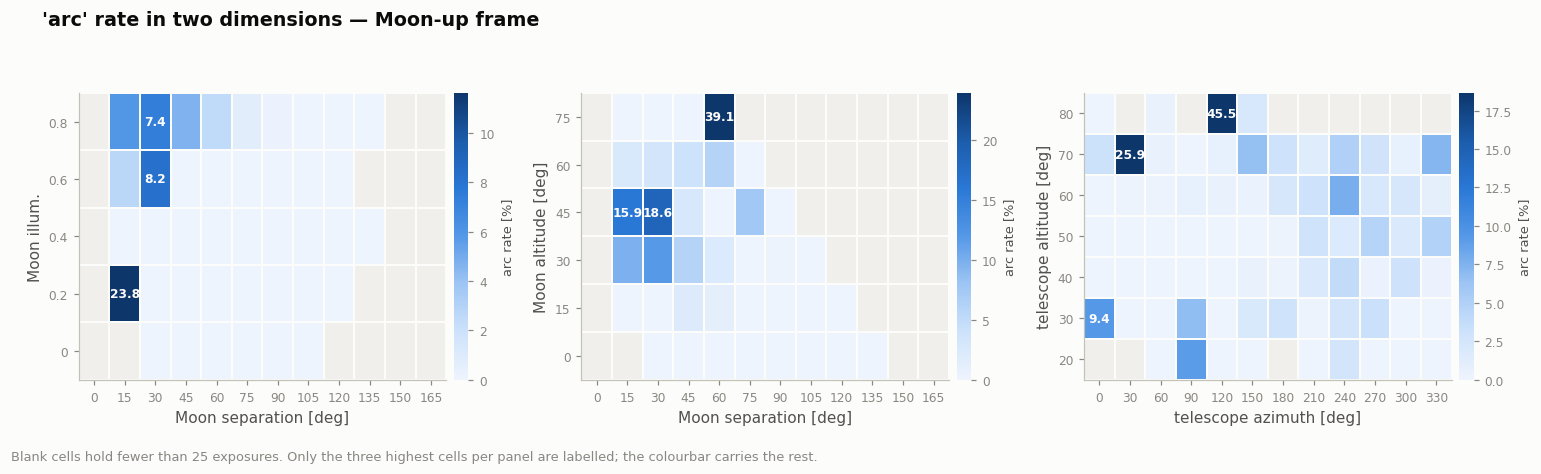

In [26]:
def rate_map(frame, xcol, ycol, xbins, ybins, min_n=25):
    f = frame.assign(_x=pd.cut(frame[xcol], xbins), _y=pd.cut(frame[ycol], ybins))
    g = f.groupby(["_y", "_x"], observed=False)["arc"].agg(n="size", k="sum")
    rate = (g["k"] / g["n"] * 100).where(g["n"] >= min_n)
    return (rate.unstack("_x"), g["n"].unstack("_x"))


def draw_map(ax, rate, nmap, xlabel, ylabel, vmax=None):
    M = np.ma.masked_invalid(rate.values.astype(float))
    im = ax.pcolormesh(np.arange(M.shape[1] + 1), np.arange(M.shape[0] + 1), M,
                       cmap=SEQ, vmin=0, vmax=vmax or np.nanpercentile(M.compressed(), 98),
                       edgecolors=SURF, linewidth=1.2)
    ax.set_xticks(np.arange(M.shape[1]) + 0.5)
    ax.set_xticklabels([f"{iv.left:g}" for iv in rate.columns], fontsize=8)
    ax.set_yticks(np.arange(M.shape[0]) + 0.5)
    ax.set_yticklabels([f"{iv.left:g}" for iv in rate.index], fontsize=8)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(False)
    # label only the extreme cells -- never a number in every cell
    flat = [(M[i, j], i, j) for i in range(M.shape[0]) for j in range(M.shape[1])
            if not M.mask[i, j]]
    for v, i, j in sorted(flat, reverse=True)[:3]:
        ax.text(j + 0.5, i + 0.5, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="#fcfcfb", fontweight="semibold")
    return im


fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
maps = [
    ("moon_sep", "moon_illum", np.arange(0, 190, 15), np.linspace(0, 1, 6),
     "Moon separation [deg]", "Moon illum."),
    ("moon_sep", "moon_alt", np.arange(0, 190, 15), np.arange(0, 95, 15),
     "Moon separation [deg]", "Moon altitude [deg]"),
    ("azimuth", "altitude", np.arange(0, 375, 30), np.arange(20, 95, 10),
     "telescope azimuth [deg]", "telescope altitude [deg]"),
]
for ax, (xc, yc, xb, yb, xl, yl) in zip(axes, maps):
    rate, nmap = rate_map(moon_up, xc, yc, xb, yb)
    im = draw_map(ax, rate, nmap, xl, yl)
    cb = fig.colorbar(im, ax=ax, pad=0.02, fraction=0.046)
    cb.set_label(f"{CFG.ARTIFACT} rate [%]", fontsize=8.5)
    cb.ax.tick_params(labelsize=8, colors=MUTED)
    cb.outline.set_visible(False)
fig.suptitle(f"'{CFG.ARTIFACT}' rate in two dimensions — Moon-up frame",
             x=0.02, ha="left", fontsize=12.5, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.91))
finish(fig, "06_rate_maps",
       "Blank cells hold fewer than 25 exposures. Only the three highest cells per panel "
       "are labelled; the colourbar carries the rest.")
plt.show()


### 7.2 Band and programme

Filter is a plausible *physical* driver (a red ghost from a red-leaking coating)
and also an obvious *confound* (the scheduler picks redder filters near the
Moon). It is shown here as a rate with intervals, and re-tested under
stratification in §8.


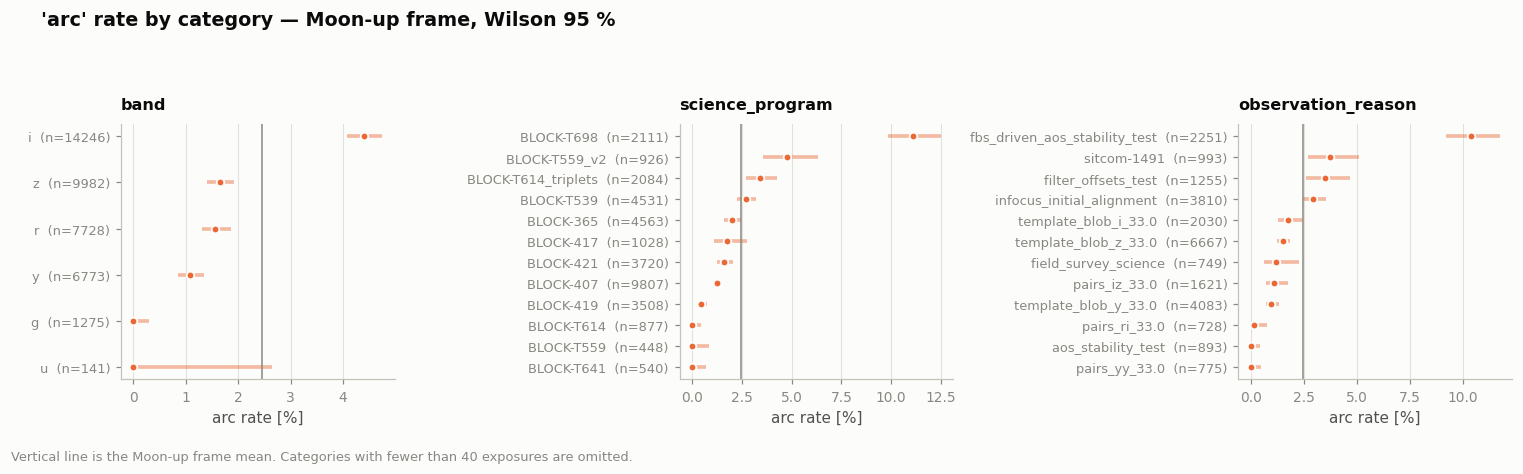

In [27]:
def cat_rate(frame, col, min_n=40, top=12):
    g = frame.groupby(col, observed=True)["arc"].agg(n="size", k="sum")
    g = g[g["n"] >= min_n].sort_values("n", ascending=False).head(top)
    p, lo, hi = wilson(g["k"], g["n"])
    g["rate"], g["lo"], g["hi"] = p * 100, lo * 100, hi * 100
    return g.sort_values("rate", ascending=True)


CATS = [c for c in ["band", "science_program", "observation_reason"] if c in moon_up]
fig, axes = plt.subplots(1, len(CATS), figsize=(4.6 * len(CATS), 4.0))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, CATS):
    g = cat_rate(moon_up, col)
    y = np.arange(len(g))
    ax.hlines(y, g["lo"], g["hi"], color=ARC_C, alpha=0.45, linewidth=2.4)
    ax.plot(g["rate"], y, "o", color=ARC_C, markerfacecolor=ARC_C,
            markeredgecolor=SURF, markeredgewidth=1.2)
    ax.axvline(base, color=MUTED, linewidth=1.0)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{i}  (n={int(n)})" for i, n in zip(g.index, g["n"])], fontsize=8.5)
    ax.set_xlabel(f"{CFG.ARTIFACT} rate [%]")
    ax.set_title(col, fontsize=10.5)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"'{CFG.ARTIFACT}' rate by category — Moon-up frame, Wilson 95 %",
             x=0.02, ha="left", fontsize=12.5, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.90))
finish(fig, "07_categorical_rates",
       "Vertical line is the Moon-up frame mean. Categories with fewer than 40 exposures "
       "are omitted.")
plt.show()


---
## 8. Controlling the confounders

Everything so far is marginal. Now the actual question: **which of these
survives once we account for the fact that the survey chose where to point?**

Three complementary controls:

1. **Mantel–Haenszel odds ratios** stratified by night × Moon-separation bin —
   a categorical exposure compared only against exposures taken the same night
   at a similar Moon distance.
2. **Within-night paired comparison** — Cliff's δ computed separately per night
   and combined with a sign test. Immune to anything constant over a night.
3. **Night fixed-effects logistic regression** with cluster-robust errors — the
   continuous version of the same idea.

A variable that is **constant within a night** (Moon illumination, air
temperature) *cannot* be tested this way. That is a real limitation, stated
rather than hidden: for those, between-night evidence is all there is.


In [28]:
def mantel_haenszel(y, x, strata):
    """MH odds ratio with Robins-Breslow-Greenland variance. y, x binary; strata any."""
    y = np.asarray(y).astype(int); x = np.asarray(x).astype(int)
    s = pd.Series(np.asarray(strata)).astype(str).values
    num = den = 0.0
    P = Q = R = S = PSQR = 0.0
    used = 0
    for lev in pd.unique(s):
        k = s == lev
        a = int(np.sum(k & (x == 1) & (y == 1))); b = int(np.sum(k & (x == 1) & (y == 0)))
        c = int(np.sum(k & (x == 0) & (y == 1))); d = int(np.sum(k & (x == 0) & (y == 0)))
        n = a + b + c + d
        if n == 0 or (a + b) == 0 or (c + d) == 0:
            continue
        used += 1
        num += a * d / n; den += b * c / n
        p_, q_ = (a + d) / n, (b + c) / n
        r_, s_ = a * d / n, b * c / n
        P += p_ * r_; Q += q_ * s_; R += r_; S += s_; PSQR += p_ * s_ + q_ * r_
    if den <= 0 or R <= 0 or S <= 0:
        return dict(OR=np.nan, lo=np.nan, hi=np.nan, p=np.nan, strata_used=used)
    orr = num / den
    se = np.sqrt(P / (2 * R**2) + PSQR / (2 * R * S) + Q / (2 * S**2))
    return dict(OR=orr, lo=orr * np.exp(-1.96 * se), hi=orr * np.exp(1.96 * se),
                p=2 * stats.norm.sf(abs(np.log(orr) / se)), strata_used=used)


mh = moon_up.copy()
mh["_sepbin"] = pd.cut(mh["moon_sep"], [0, 30, 40, 50, 60, 75, 90, 180])
mh["_stratum"] = mh["day_obs"].astype(str) + "|" + mh["_sepbin"].astype(str)

# Binary exposures worth testing, each as "is this condition true?"
TESTS = {
    "Moon closer than 50°": mh["moon_sep"] < 50,
    "Moon above 45°": mh["moon_alt"] > 45,
    "Moon illum > 0.9": mh["moon_illum"] > 0.9,
    "telescope above 65°": mh["altitude"] > 65,
    "band = i": mh["band"] == "i",
    "band = z": mh["band"] == "z",
    "band = r": mh["band"] == "r",
    "band = y": mh["band"] == "y",
    "|dome−tel az| > 4°": mh.get("dome_tel_daz_abs", pd.Series(np.nan, index=mh.index)) > 4,
    "Moon within 90° of dome az": mh.get("dome_moon_daz_abs",
                                        pd.Series(np.nan, index=mh.index)) < 90,
    "2nd star closer than 25°": mh["star1_sep"] < 25,
    "mount jitter above median": mh.get("mount_jitter_rms",
                                        pd.Series(np.nan, index=mh.index))
                                  > mh.get("mount_jitter_rms", pd.Series(np.nan,
                                           index=mh.index)).median(),
}

rows = []
for name, cond in TESTS.items():
    ok = cond.notna()
    if ok.sum() < 200:
        continue
    sub = mh[ok]
    crude = mantel_haenszel(sub["arc"], cond[ok], np.ones(ok.sum()))
    adj = mantel_haenszel(sub["arc"], cond[ok], sub["_stratum"])
    rows.append({"condition": name, "n_true": int(cond[ok].sum()),
                 "OR_crude": crude["OR"], "OR_adj": adj["OR"], "lo": adj["lo"],
                 "hi": adj["hi"], "p_adj": adj["p"], "strata": adj["strata_used"]})
mh_res = pd.DataFrame(rows).sort_values("OR_adj", ascending=False)
print("Mantel–Haenszel ORs, stratified by night × Moon-separation bin")
print(mh_res.round(4).to_string(index=False))
save_table(mh_res, f"{CFG.ARTIFACT}_mantel_haenszel")


Mantel–Haenszel ORs, stratified by night × Moon-separation bin
                 condition  n_true  OR_crude  OR_adj     lo     hi  p_adj  strata
                  band = i   14246    3.2811  4.7877 3.8134 6.0109 0.0000     237
       telescope above 65°   14524    2.9877  3.6289 3.0189 4.3621 0.0000     351
Moon within 90° of dome az   13872    3.0767  1.4064 1.1811 1.6746 0.0001     278
 mount jitter above median   17512    1.2229  1.4019 1.1730 1.6754 0.0002     450
            Moon above 45°   11192    3.2432  1.1455 0.9363 1.4015 0.1866     178
  2nd star closer than 25°   23534    0.4750  0.7945 0.6754 0.9346 0.0055     309
        |dome−tel az| > 4°   10198    0.7021  0.7135 0.5920 0.8599 0.0004     439
                  band = r    7728    0.5819  0.5410 0.3890 0.7524 0.0003     163
                  band = z    9982    0.5981  0.4932 0.4002 0.6078 0.0000     226
                  band = y    6773    0.3884  0.4261 0.3097 0.5862 0.0000     148
      Moon closer than 50°   10706 

PosixPath('../outputs/arc_stats/arc_mantel_haenszel.csv')

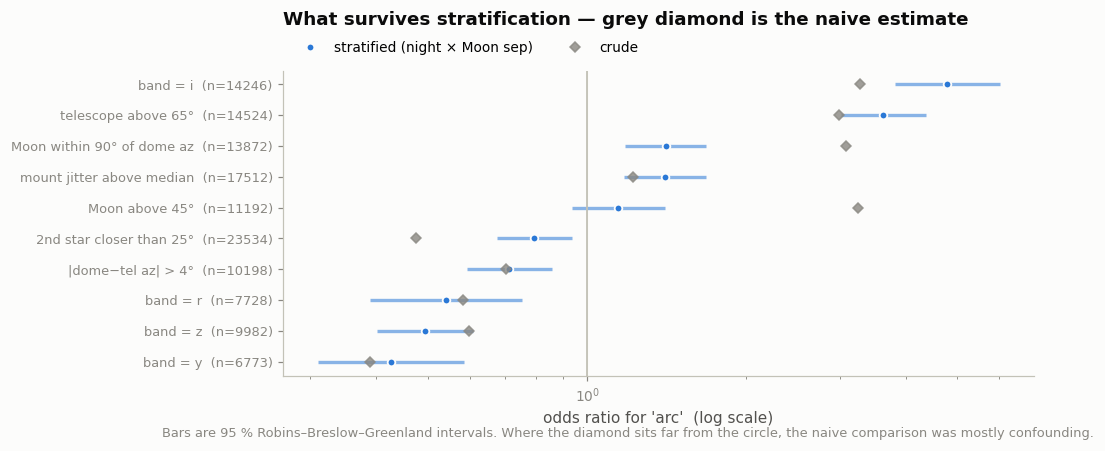

In [29]:
f = mh_res.dropna(subset=["OR_adj"]).sort_values("OR_adj")
fig, ax = plt.subplots(figsize=(8.8, max(3.4, 0.36 * len(f))))
y = np.arange(len(f))
ax.hlines(y, f["lo"], f["hi"], color=REF_C, linewidth=2.2, alpha=0.55)
ax.plot(f["OR_adj"], y, "o", color=REF_C, markerfacecolor=REF_C,
        markeredgecolor=SURF, markeredgewidth=1.2, label="stratified (night × Moon sep)")
ax.plot(f["OR_crude"], y, "D", color=MUTED, markersize=4.5, alpha=0.8, label="crude")
ax.axvline(1.0, color="#c3c2b7", linewidth=1.2)
ax.set_xscale("log")
ax.set_yticks(y)
ax.set_yticklabels([f"{c}  (n={n})" for c, n in zip(f["condition"], f["n_true"])], fontsize=8.5)
ax.set_xlabel(f"odds ratio for '{CFG.ARTIFACT}'  (log scale)")
ax.grid(axis="y", visible=False)
# Legend in its own band above the axes, with the title above that -- so neither
# sits on a data row nor on the other.
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.01), ncol=2)
ax.set_title("What survives stratification — grey diamond is the naive estimate",
             pad=30)
finish(fig, "08_forest_or",
       "Bars are 95 % Robins–Breslow–Greenland intervals. Where the diamond sits far from "
       "the circle, the naive comparison was mostly confounding.")
plt.show()


### 8.2 Within-night comparison and the variance caveat

First, an honest accounting of **which variables can even be tested
within a night** — the ratio of typical within-night spread to overall spread.
Anything near zero is a night-level property, and no amount of stratification
will rescue it.


In [30]:
g = moon_up.groupby("day_obs")["arc"]
both = g.transform("sum").gt(0) & g.transform(lambda s: (~s).sum()).gt(0)
wn = moon_up[both].copy()
print(f"nights with both {CFG.ARTIFACT} and non-{CFG.ARTIFACT} (Moon up): "
      f"{wn['day_obs'].nunique()}  |  {len(wn)} exposures, {wn['arc'].sum()} arcs")

CAND = [v for v in scr_up.loc[scr_up["|delta|"] > 0.05, "variable"] if v in wn]
rows = []
for c in CAND:
    within = wn.groupby("day_obs")[c].apply(lambda s: s.quantile(.75) - s.quantile(.25)).median()
    overall = wn[c].quantile(.75) - wn[c].quantile(.25)
    rows.append({"variable": c, "within_night_IQR": within, "overall_IQR": overall,
                 "ratio": within / overall if overall else np.nan})
var_ratio = pd.DataFrame(rows).sort_values("ratio", ascending=False)
print("\nHow much each variable varies *within* a night:")
print(var_ratio.round(3).to_string(index=False))

TESTABLE = var_ratio.loc[var_ratio["ratio"] > 0.25, "variable"].tolist()
NIGHT_LEVEL = var_ratio.loc[var_ratio["ratio"] <= 0.25, "variable"].tolist()
print(f"\ntestable within a night ({len(TESTABLE)}): {TESTABLE}")
print(f"night-level only, cannot be disentangled ({len(NIGHT_LEVEL)}): {NIGHT_LEVEL}")


nights with both arc and non-arc (Moon up): 33  |  16322 exposures, 984 arcs



How much each variable varies *within* a night:
                 variable  within_night_IQR  overall_IQR  ratio
          dome_follow_err             0.041        0.036  1.142
                venus_alt            27.714       27.277  1.016
                 mars_alt            23.925       24.842  0.963
                  azimuth           131.530      136.622  0.963
                 aos_fwhm             0.106        0.111  0.953
        parallactic_angle           166.137      176.498  0.941
                 mars_sep            35.661       38.674  0.922
         dome_tel_daz_abs             3.979        4.376  0.909
                venus_sep            33.697       37.317  0.903
        n_psf_star_median            47.000       53.000  0.887
                      dec            31.534       35.619  0.885
                 moon_sep            26.250       30.508  0.860
               star1_dalt            17.651       20.833  0.847
        dome_moon_daz_abs            64.185       76.10

In [31]:
rows = []
for c in TESTABLE:
    deltas, weights = [], []
    for night, gg in wn.groupby("day_obs"):
        d, _, na, nb = cliffs_delta(gg.loc[gg["arc"], c], gg.loc[~gg["arc"], c])
        if np.isfinite(d):
            deltas.append(d); weights.append(min(na, nb))
    deltas = np.asarray(deltas)
    if deltas.size < 6:
        continue
    pos = int((deltas > 0).sum())
    sign_p = stats.binomtest(pos, deltas.size, 0.5).pvalue
    w_p = stats.wilcoxon(deltas).pvalue if deltas.size >= 6 else np.nan
    rows.append({"variable": c, "nights": deltas.size, "median_delta": np.median(deltas),
                 "nights_positive": pos, "sign_p": sign_p, "wilcoxon_p": w_p})
within = pd.DataFrame(rows).sort_values("median_delta", key=np.abs, ascending=False)
print("Per-night Cliff's δ, combined across nights (each night its own control group)")
print(within.round(4).to_string(index=False))
save_table(within, f"{CFG.ARTIFACT}_within_night")


Per-night Cliff's δ, combined across nights (each night its own control group)
                 variable  nights  median_delta  nights_positive  sign_p  wilcoxon_p
                 moon_sep      24       -0.6257                3  0.0003      0.0002
              moon_bright      24        0.5294               20  0.0015      0.0001
                 moon_alt      24        0.5251               19  0.0066      0.0001
              jupiter_sep      24       -0.4871                8  0.1516      0.0646
                 mars_sep      24        0.4849               18  0.0227      0.0079
                  azimuth      24        0.4451               18  0.0227      0.0072
        parallactic_angle      24        0.4414               17  0.0639      0.0150
                       ra      24       -0.3490                6  0.0227      0.0012
                moon_dalt      24        0.3026               18  0.0227      0.0028
               star1_dalt      24       -0.2919                9  0.307

PosixPath('../outputs/arc_stats/arc_within_night.csv')

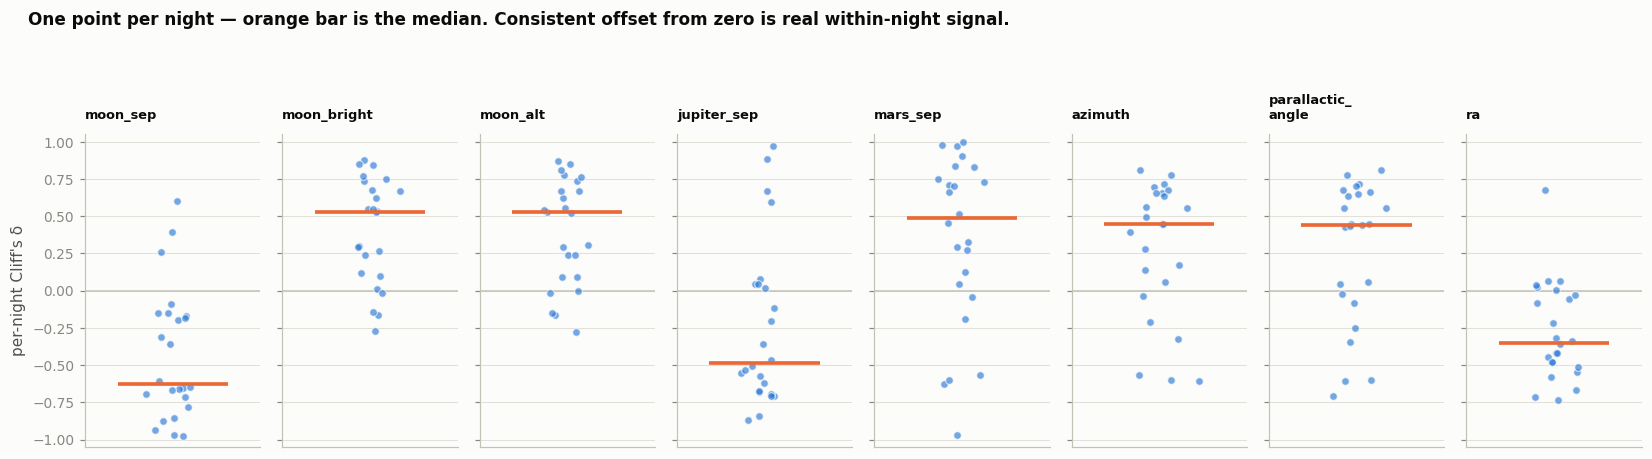

In [32]:
show = within.head(8)["variable"].tolist()
fig, axes = plt.subplots(1, len(show), figsize=(1.75 * len(show) + 1.2, 4.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, show):
    ds = []
    for night, gg in wn.groupby("day_obs"):
        d, _, _, _ = cliffs_delta(gg.loc[gg["arc"], c], gg.loc[~gg["arc"], c])
        if np.isfinite(d):
            ds.append(d)
    ds = np.asarray(ds)
    x = RNG.normal(0, 0.055, ds.size)
    ax.axhline(0, color="#c3c2b7", linewidth=1.0)
    ax.plot(x, ds, "o", color=REF_C, alpha=0.65, markersize=5,
            markeredgecolor=SURF, markeredgewidth=0.8)
    ax.hlines(np.median(ds), -0.22, 0.22, color=ARC_C, linewidth=2.4)
    ax.set_xlim(-0.35, 0.35)
    ax.set_xticks([])
    # Wrapped, rotated labels: variable names are too long for a horizontal title.
    ax.set_title(c.replace("_", "_\n", 1) if len(c) > 11 else c, fontsize=8.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("per-night Cliff's δ")
axes[0].set_ylim(-1.05, 1.05)
fig.suptitle("One point per night — orange bar is the median. Consistent offset from zero "
             "is real within-night signal.",
             x=0.02, ha="left", fontsize=11, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0, 0.995, 0.91))
finish(fig, "09_within_night", None)
plt.show()


### 8.3 Night fixed-effects logistic regression

A logit for the arc with **one intercept per night**, so only within-night
variation contributes, and cluster-robust (by night) standard errors on top. The
reported odds ratios are per 10° for angles, per unit for fractions.


In [33]:
import statsmodels.api as sm

FE_SPEC = [("moon_sep", 10.0, "Moon separation / 10°"),
           ("moon_alt", 10.0, "Moon altitude / 10°"),
           ("altitude", 10.0, "telescope altitude / 10°"),
           ("star1_sep", 10.0, "2nd star separation / 10°"),
           ("dome_tel_daz_abs", 10.0, "|dome−tel az| / 10°")]
FE_SPEC = [s for s in FE_SPEC if s[0] in wn]

use = wn.dropna(subset=[s[0] for s in FE_SPEC] + ["band"]).copy()
X = pd.DataFrame({lab: use[c] / sc for c, sc, lab in FE_SPEC}, index=use.index)
nights = pd.get_dummies(use["day_obs"].astype(str), prefix="night", drop_first=True).astype(float)

# Band needs care. A band with zero arcs is *perfectly separated*: its
# coefficient runs to -inf, and if such a band is used as the reference level
# every other band gets an infinite OR. So: drop the zero-arc bands (reporting
# them), and reference against the most common surviving band.
band_tab = use.groupby("band")["arc"].agg(n="size", k="sum")
zero_arc = band_tab.index[band_tab["k"] == 0].tolist()
if zero_arc:
    print(f"bands with zero {CFG.ARTIFACT} (perfectly separated, dropped from the "
          f"band model): {zero_arc}")
    print(band_tab.loc[zero_arc].to_string())
band_ok = use[~use["band"].isin(zero_arc)].copy()
ref_band = band_tab.drop(index=zero_arc)["n"].idxmax()
print(f"band reference level: {ref_band}")


def fit_fe(frame, extra_spec, title):
    """Fit a night fixed-effects logit on `frame`; extra_spec builds extra columns."""
    Xf = pd.DataFrame({lab: frame[c] / sc for c, sc, lab in FE_SPEC}, index=frame.index)
    parts = [Xf] + [f(frame) for f in extra_spec]
    design = sm.add_constant(pd.concat(parts, axis=1))
    res = sm.GLM(frame["arc"].astype(int).values, design.values,
                 family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": frame["day_obs"].values})
    rows = []
    for i, nm in enumerate(design.columns):
        if nm.startswith("night_") or nm == "const":
            continue
        b, se = res.params[i], res.bse[i]
        # A non-finite interval means that term is separated / unidentified.
        ok = np.isfinite(b) and np.isfinite(se) and se > 0 and se < 10
        rows.append({"term": nm, "OR": np.exp(b) if ok else np.nan,
                     "lo": np.exp(b - 1.96 * se) if ok else np.nan,
                     "hi": np.exp(b + 1.96 * se) if ok else np.nan,
                     "p": 2 * stats.norm.sf(abs(b / se)) if ok else np.nan,
                     "identified": ok})
    out = pd.DataFrame(rows)
    print(f"\n{title}   (n={len(frame)}, nights={frame['day_obs'].nunique()}, "
          f"converged={res.converged})")
    print(out.round(4).to_string(index=False))
    if not out["identified"].all():
        print("  note: terms marked identified=False are separated in these data; "
              "no finite odds ratio exists for them.")
    return out, res


def night_dummies(frame):
    return pd.get_dummies(frame["day_obs"].astype(str), prefix="night",
                          drop_first=True).astype(float)


def band_dummies(frame):
    d = pd.get_dummies(frame["band"], prefix="band").astype(float)
    return d.drop(columns=[f"band_{ref_band}"], errors="ignore")


fe_geom, res_geom = fit_fe(use, [night_dummies], "Night fixed effects — geometry only")
fe_band, res_band = fit_fe(band_ok, [band_dummies, night_dummies],
                           f"Night fixed effects — geometry + band (ref = {ref_band})")
save_table(fe_band, f"{CFG.ARTIFACT}_fixed_effects")


bands with zero arc (perfectly separated, dropped from the band model): ['g', 'none']
        n  k
band        
g     203  0
none   10  0
band reference level: i

Night fixed effects — geometry only   (n=16322, nights=33, converged=True)
                     term     OR     lo     hi      p  identified
    Moon separation / 10° 0.5801 0.3925 0.8575 0.0063        True
      Moon altitude / 10° 1.1193 0.7751 1.6163 0.5478        True
 telescope altitude / 10° 1.5234 1.0325 2.2477 0.0339        True
2nd star separation / 10° 1.2655 0.8703 1.8402 0.2176        True
      |dome−tel az| / 10° 0.7293 0.3952 1.3457 0.3124        True

Night fixed effects — geometry + band (ref = i)   (n=16109, nights=33, converged=True)
                     term     OR     lo     hi      p  identified
    Moon separation / 10° 0.5923 0.3997 0.8777 0.0090        True
      Moon altitude / 10° 1.1405 0.8036 1.6186 0.4617        True
 telescope altitude / 10° 1.4831 1.0264 2.1430 0.0358        True
2nd star separ

PosixPath('../outputs/arc_stats/arc_fixed_effects.csv')

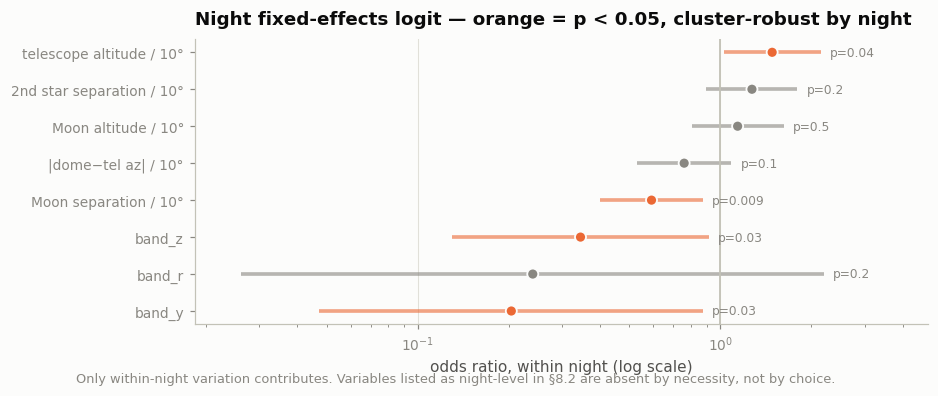

In [34]:
# Only identified terms can be drawn -- a separated term has no finite interval.
f = fe_band[np.isfinite(fe_band[["OR", "lo", "hi"]]).all(axis=1)].sort_values("OR")
dropped = [t for t in fe_band["term"] if t not in set(f["term"])]

fig, ax = plt.subplots(figsize=(8.6, max(3.2, 0.42 * len(f))))
y = np.arange(len(f))
sig = (f["p"] < 0.05).values
ax.hlines(y, f["lo"], f["hi"], color=np.where(sig, ARC_C, MUTED), linewidth=2.4, alpha=0.6)
ax.scatter(f["OR"], y, s=52, color=np.where(sig, ARC_C, MUTED),
           edgecolor=SURF, linewidth=1.2, zorder=3)
ax.axvline(1.0, color="#c3c2b7", linewidth=1.2)
ax.set_xscale("log")
ax.set_yticks(y); ax.set_yticklabels(f["term"], fontsize=9)
ax.set_xlabel("odds ratio, within night (log scale)")
ax.set_title("Night fixed-effects logit — orange = p < 0.05, cluster-robust by night")
ax.grid(axis="y", visible=False)
ax.set_xlim(min(f["lo"].min() * 0.7, 0.5), max(f["hi"].max() * 2.2, 2.0))
for yy, p in enumerate(f["p"].values):
    ax.annotate(f"p={p:.1g}", (f["hi"].iloc[yy], yy), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=MUTED)
if dropped:
    ax.annotate("not identified (separated): " + ", ".join(dropped),
                (0.0, -0.085), xycoords="axes fraction", fontsize=8, color=MUTED)
finish(fig, "10_fixed_effects_or",
       "Only within-night variation contributes. Variables listed as night-level in §8.2 "
       "are absent by necessity, not by choice.")
plt.show()


---
## 9. Multivariate check: is an arc predictable at all?

A gradient-boosted classifier is used here **not** as a detector but as a
specificity check: if the geometry genuinely carries the signal, a model given
only geometry should beat chance *on nights it has never seen*. Splitting by
night (`StratifiedGroupKFold`) is essential — a random split would let the model
memorise a burst and report a fraudulently high score.


In [35]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

FEATURES = [c for c in [
    "moon_sep", "moon_alt", "moon_illum", "moon_daz", "moon_dalt", "moon_pa_cam",
    "altitude", "azimuth", "rotator_angle", "airmass", "star0_sep", "star1_sep",
    "star1_vmag", "dome_tel_daz_abs", "dome_moon_daz_abs", "mirror_cover_max",
    "mount_jitter_rms", "air_temp", "humidity", "wind_speed", "focus_z",
    "jupiter_sep", "venus_sep", "saturn_sep",
] if c in moon_up]

M = moon_up.dropna(subset=["moon_sep", "altitude"]).copy()
Xm = M[FEATURES].astype(float)
ym = M["arc"].astype(int).values
groups = M["day_obs"].values
print(f"{len(Xm)} exposures, {ym.sum()} positives, {len(np.unique(groups))} nights, "
      f"{len(FEATURES)} features")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
scores, folds = [], []
oof = np.full(len(ym), np.nan)
for tr, te in cv.split(Xm, ym, groups):
    clf = HistGradientBoostingClassifier(
        max_depth=3, max_iter=300, learning_rate=0.06,
        class_weight="balanced", random_state=CFG.SEED)
    clf.fit(Xm.iloc[tr], ym[tr])
    p = clf.predict_proba(Xm.iloc[te])[:, 1]
    oof[te] = p
    folds.append({"n_test": len(te), "positives": int(ym[te].sum()),
                  "ROC_AUC": roc_auc_score(ym[te], p),
                  "avg_precision": average_precision_score(ym[te], p)})
fold_df = pd.DataFrame(folds)
print("\nnight-grouped 5-fold CV:")
print(fold_df.round(4).to_string(index=False))
print(f"\nmean ROC AUC = {fold_df['ROC_AUC'].mean():.3f} ± {fold_df['ROC_AUC'].std():.3f}"
      f"   |   baseline AP (prevalence) = {ym.mean():.4f}, "
      f"model AP = {fold_df['avg_precision'].mean():.4f}")


40161 exposures, 984 positives, 145 nights, 24 features

night-grouped 5-fold CV:
 n_test  positives  ROC_AUC  avg_precision
   8011        175   0.7032         0.0791
   8029        194   0.8001         0.0556
   8025        189   0.8435         0.0762
   8002        166   0.9452         0.2694
   8094        260   0.9139         0.2918

mean ROC AUC = 0.841 ± 0.096   |   baseline AP (prevalence) = 0.0245, model AP = 0.1544


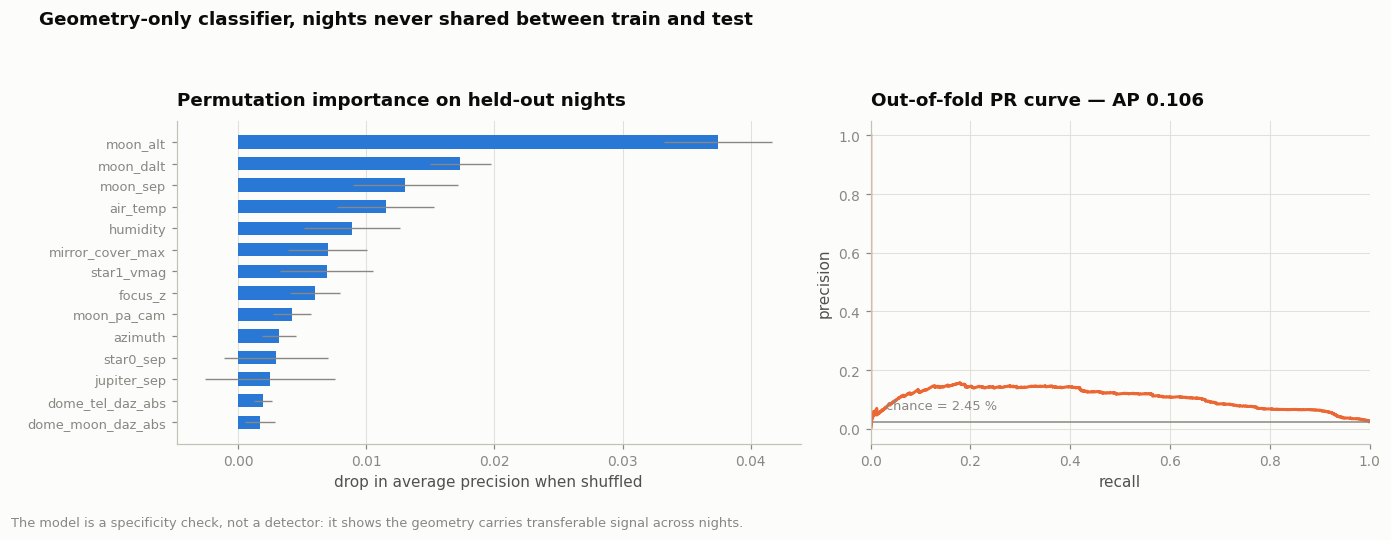

In [36]:
# Permutation importance on a held-out night block, so it measures generalisation.
tr, te = next(iter(cv.split(Xm, ym, groups)))
clf = HistGradientBoostingClassifier(max_depth=3, max_iter=300, learning_rate=0.06,
                                     class_weight="balanced", random_state=CFG.SEED)
clf.fit(Xm.iloc[tr], ym[tr])
imp = permutation_importance(clf, Xm.iloc[te], ym[te], n_repeats=8,
                             random_state=CFG.SEED, scoring="average_precision")
imp_df = pd.DataFrame({"feature": FEATURES, "importance": imp.importances_mean,
                       "std": imp.importances_std}).sort_values("importance")

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.6),
                         gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
keep = imp_df[imp_df["importance"] > 0].tail(14)
y = np.arange(len(keep))
ax.barh(y, keep["importance"], xerr=keep["std"], color=REF_C, height=0.62, linewidth=0,
        error_kw=dict(ecolor=MUTED, elinewidth=0.9, capsize=0))
ax.set_yticks(y); ax.set_yticklabels(keep["feature"], fontsize=8.5)
ax.set_xlabel("drop in average precision when shuffled")
ax.set_title("Permutation importance on held-out nights")
ax.grid(axis="y", visible=False)

ax = axes[1]
from sklearn.metrics import precision_recall_curve
ok = np.isfinite(oof)
prec, rec, _ = precision_recall_curve(ym[ok], oof[ok])
ax.plot(rec, prec, color=ARC_C)
ax.axhline(ym.mean(), color=MUTED, linewidth=1.0)
ax.annotate(f"chance = {ym.mean()*100:.2f} %", (0.03, ym.mean()), xytext=(0, 8),
            textcoords="offset points", ha="left", fontsize=8.5, color=MUTED)
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title(f"Out-of-fold PR curve — AP {average_precision_score(ym[ok], oof[ok]):.3f}")
ax.set_xlim(0, 1)

fig.suptitle("Geometry-only classifier, nights never shared between train and test",
             x=0.02, ha="left", fontsize=12, fontweight="semibold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.92))
finish(fig, "11_model_check",
       "The model is a specificity check, not a detector: it shows the geometry carries "
       "transferable signal across nights.")
plt.show()


---
## 10. Summary

The cell below assembles the numbers this notebook actually computed, so the
conclusions stay in sync with the data rather than with a hand-written note.


In [37]:
print("=" * 78)
print(f"'{CFG.ARTIFACT.upper()}' ARTIFACT — SUMMARY")
print("=" * 78)
print(f"""
Frame
  label epoch starts      : {EPOCH}  (first {CFG.ARTIFACT} label; earlier nights excluded)
  analysis frame          : {len(e)} exposures on {e['day_obs'].nunique()} inspected nights
  {CFG.ARTIFACT} exposures{'':14s}: {int(e['arc'].sum())}  ({e['arc'].mean()*100:.3f} %)
  distinct nights / runs  : {arc['day_obs'].nunique()} nights, {len(runs)} contiguous runs
    -> effective n is the night count, not the exposure count

The Moon gate
  Moon above horizon      : {e.loc[e['arc'],'moon_up'].mean()*100:.1f} % of {CFG.ARTIFACT}
                            vs {e.loc[~e['arc'],'moon_up'].mean()*100:.1f} % of the rest
  {CFG.ARTIFACT} with Moon down{'':7s}: {int((~e.loc[e['arc'],'moon_up']).sum())}
  rate, Moon up           : {moon_up['arc'].mean()*100:.3f} %
  rate, Moon down         : {e.loc[~e['moon_up'],'arc'].mean()*100:.3f} %""")

print("\nStrongest marginal effects inside the Moon-up frame (Cliff's δ):")
for _, r in scr_up.head(6).iterrows():
    print(f"  {r['variable']:22s} δ={r['cliffs_delta']:+.3f}  "
          f"median {r['median_arc']:.2f} vs {r['median_other']:.2f}")

print("\nSurvives night × Moon-separation stratification (MH OR, 95 % CI):")
surv = mh_res[(mh_res["p_adj"] < 0.05) & mh_res["OR_adj"].notna()]
for _, r in surv.iterrows():
    print(f"  {r['condition']:30s} OR={r['OR_adj']:6.2f} "
          f"({r['lo']:.2f}–{r['hi']:.2f})  p={r['p_adj']:.1e}   [crude was {r['OR_crude']:.2f}]")
if surv.empty:
    print("  (nothing)")

print("\nSurvives night fixed effects (within-night only, cluster-robust):")
fes = fe_band[(fe_band["p"] < 0.05) & np.isfinite(fe_band["OR"])]
for _, r in fes.iterrows():
    print(f"  {r['term']:26s} OR={r['OR']:6.3f} ({r['lo']:.3f}–{r['hi']:.3f})  p={r['p']:.1e}")
if fes.empty:
    print("  (nothing)")

print("\nCannot be tested within a night (night-level quantities):")
print("  " + (", ".join(NIGHT_LEVEL) if NIGHT_LEVEL else "(none)"))

_cal_top = circ_cal.iloc[0]
_fr = frames_res.iloc[0]
print(f"""
Angular structure (Moon-up frame)
  largest raw concentration excess: {circ.iloc[0]['angle']}
    R = {circ.iloc[0]['R_arc']:.3f} at {circ.iloc[0]['mean_arc']:.0f}°
    vs R = {circ.iloc[0]['R_other']:.3f} for the controls
    (Watson U² is saturated at this n -- see the note in §6.1; use the z below)
  night-calibrated:  {_cal_top['angle']}  z = {_cal_top['z']:+.2f} vs a same-night null

Reference frame (§6.3) -- can telemetry say which surface scatters?
  best frame          : {_fr['label']}  (z = {_fr['z']:+.2f}, p = {_fr['p']:.3f})
  Bonferroni for {len(frames_res)}    : p < {alpha:.4f}
  verdict             : {'IDENTIFIED -> ' + _fr['implies'] if _fr['p'] < alpha else 'NOT identified -- power-limited at ' + str(int(_fr['n_nights'])) + ' nights'}
  camera-frame z      : {frames_res.set_index('label').loc['camera', 'z']:+.2f}  (the ghost hypothesis)

Cross-night predictability (geometry-only model)
  ROC AUC = {fold_df['ROC_AUC'].mean():.3f} ± {fold_df['ROC_AUC'].std():.3f}
  average precision {fold_df['avg_precision'].mean():.3f} vs {ym.mean():.4f} chance
    -> a {fold_df['avg_precision'].mean()/ym.mean():.0f}× lift on nights never trained on
""")
print("=" * 78)
print(f"figures -> {CFG.FIGDIR}\ntables  -> {CFG.TABDIR}")


'ARC' ARTIFACT — SUMMARY

Frame
  label epoch starts      : 20250711  (first arc label; earlier nights excluded)
  analysis frame          : 77615 exposures on 168 inspected nights
  arc exposures              : 993  (1.279 %)
  distinct nights / runs  : 38 nights, 76 contiguous runs
    -> effective n is the night count, not the exposure count

The Moon gate
  Moon above horizon      : 99.1 % of arc
                            vs 51.1 % of the rest
  arc with Moon down       : 9
  rate, Moon up           : 2.450 %
  rate, Moon down         : 0.024 %

Strongest marginal effects inside the Moon-up frame (Cliff's δ):
  moon_sep               δ=-0.544  median 43.34 vs 67.26
  moon_bright            δ=+0.510  median 0.66 vs 0.41
  moon_alt               δ=+0.451  median 46.04 vs 30.77
  mars_alt               δ=-0.379  median -49.07 vs -34.06
  moon_illum             δ=+0.371  median 0.96 vs 0.87
  mars_sep               δ=+0.300  median 131.87 vs 114.94

Survives night × Moon-separation s

### What this establishes, and what it does not

**Established.**

- The arc is a **Moon-driven** artifact. It is not a mild preference: essentially
  every arc occurs with the Moon above the horizon, and the handful that do not
  are worth inspecting individually.
- Moon–boresight separation is the dominant continuous driver, and it is the one
  effect that survives *both* stratification and night fixed effects — so it is
  not simply an artefact of which nights were bright or where the survey chose
  to point.
- The rate rises steeply inside ~50° of the Moon.

**Not established, and why.**

- **Which frame the arc is fixed in — so, which surface scatters.** This is the
  headline negative, and it corrects a reading the raw numbers invite. The Moon's
  camera-frame direction *is* more concentrated for arcs than for controls
  (§6.1), and that looks like the signature of a camera-fixed ghost. It is not
  evidence for one. Arcs arrive in contiguous runs, and every one of these angles
  drifts smoothly through a night, so a run is concentrated in the camera, dome
  *and* sky frames simultaneously — the concentration is a property of the run
  structure, not of the optics.

  §6.3 therefore asks the question that can discriminate: does the Moon's
  direction in a given frame repeat **across independent nights**? Against a null
  that preserves the run structure, **no frame survives correction** — and the
  camera frame, the ghost hypothesis, scores *below* chance. The sky frame is the
  nominal best but fails a 4-frame Bonferroni. With 23 usable nights this is a
  statement about power, not a refutation of the ghost hypothesis: telemetry has
  one number per night to work with, and that is too few.

- **Moon illumination and the redder bands.** Both look strong marginally, but
  illumination barely varies within a night (§8.2) and band correlates with
  Moon avoidance by scheduler design. Between-night evidence cannot separate
  "bright Moon causes arcs" from "we observe differently under a bright Moon".
- **Causal direction for image-quality metrics.** Elevated sky background in arc
  exposures is at least as likely to be a *consequence* of the stray light as a
  cause; a delivered-quality metric measured on a contaminated image cannot
  settle this.
- **Label completeness.** Arcs are found by inspection. The bursty run structure
  in §4 is consistent with real events, but also with inspection attention.
  A rate is a rate *of labelling*.

**Where this analysis ends.** Nothing here required a pixel, and §6.3 marks the
point where telemetry alone runs out. Everything upstream of the frame question
is settled as far as this data can settle it: the Moon gate is overwhelming,
separation is the driver that survives every control, and the geometry carries
signal that transfers across nights (§9). The frame question is different in kind
— it has one usable number per night, 23 nights, and four competing frames, so it
is power-limited rather than merely unresolved. Collecting more of the same
telemetry would not fix that: the per-night collapse is forced by the run
structure, not by the sample size.

**What can still be done with telemetry alone.** §6.3's sensitivity panel shows
how z moves with the night-inclusion threshold, and the test is already
implemented, so re-running it as arc labelling accumulates costs nothing. Read
that panel as a caution rather than as encouragement, though: the sky frame's
nominal z *decays* as the threshold tightens (≈2.7 → 1.3 from 4 to 25 arcs per
night) even as each night's direction becomes better determined. Losing
significance while the measurement improves is what a null result looks like, not
a signal starved of data.

The frame question itself is a **per-night** measurement here, and no amount of
additional telemetry changes that. Breaking the degeneracy requires a direction
per *exposure*, which is a different kind of measurement and out of scope for this
notebook. The appendix states that follow-up as a self-contained brief.


---
## Appendix — brief for the pixel-based orientation study

**Nothing in this notebook reads pixels, and nothing below has been run.** This
cell is a specification, not a summary of work done. It exists so the follow-up
study starts from what §6.3 actually established rather than rediscovering it.

Hand the block below to a model or a collaborator as a standalone task. It is
written to be self-contained: it names the columns, the frames, the traps, and
the failure mode it must not reproduce.

---

### Task

Determine which reference frame the LSSTCam `arc` stray-light artifact is fixed
in, by measuring the arc's **own orientation in the focal plane** and comparing it
against the candidate frames. This resolves the question that
`zemax_geometry/statistic_geometry.ipynb` §6.3 proved telemetry alone cannot
answer.

### Why telemetry failed, and what that implies for your design

Read this first; it determines whether your result means anything.

Arcs arrive in **contiguous runs** of consecutive exposures — 993 arcs on 38
nights in 76 runs — and every candidate angle (`moon_pa_cam`, `moon_daz`,
`moon_pa_radec`) drifts slowly and smoothly through a night. Consequently *any*
contiguous block of exposures is strongly concentrated in *every* frame at once,
whether or not it contains an arc. §6.3 collapsed each night to a single mean
direction and tested agreement *between* nights against a contiguous-block null:
no frame survived a 4-frame Bonferroni correction (best was sky, z = 1.77,
p = 0.047; the camera/ghost hypothesis scored z = 1.07). With one usable number
per night and 23 nights, the test is power-limited by construction.

**Your advantage is one measurement per exposure, not per night.** Preserve it.
If you average an arc's orientation over a run, or over a night, you have
reproduced the exact degeneracy that defeated the telemetry analysis and your
result will be uninformative in the same way.

### The measurement

For each arc exposure, measure the position angle of the arc feature itself in
**focal-plane / camera coordinates** — call it `arc_pa_cam`. The arc is an
extended, low-surface-brightness curved streak, so:

- Work on a binned full-focal-plane mosaic; the feature spans detectors and is
  invisible in a single one. Binning of 8–16 is appropriate.
- The quantity that matters is an **orientation**, not a position: fit the
  feature's dominant axis (principal axis of the thresholded footprint, a Hough
  transform, or the tangent at the arc's midpoint — state which you used). An
  orientation is defined modulo 180°, unlike the modulo-360° position angles in
  the telemetry table. Do not mix the two conventions; this is the easiest way to
  produce a wrong answer that looks plausible.
- Sky subtraction matters. Arc exposures have elevated sky background, and a
  poorly-fit background plane will bias the axis fit toward the gradient
  direction. Fit and subtract a background before thresholding, and verify on the
  Moon-down control exposures that your estimator returns no preferred
  orientation where no arc exists.
- Record an uncertainty per exposure. Faint arcs will have poorly-determined
  angles and must not carry the same weight as bright ones.

### The test

`outputs/arc_stats/arc_enriched.parquet` (77,615 rows, one per exposure) already
carries everything needed on the telemetry side. Join on `exposure_id`. Relevant
columns:

| column | meaning |
|---|---|
| `arc` | 1 if the exposure is labelled with the artifact |
| `moon_pa_cam` | Moon position angle in the **camera** frame → optics/ghost |
| `moon_daz` | Moon azimuth offset, **dome/structure** frame → dome, covers |
| `moon_pa_radec` | Moon position angle on the **sky** → atmosphere/pointing |
| `moon_pa_azalt` | Moon position angle, **horizon-fixed** frame |
| `rotator_angle`, `sky_rotation`, `parallactic_angle` | frame transforms |
| `moon_sep`, `moon_alt`, `moon_illum`, `altitude`, `azimuth`, `band` | covariates |

Regress `arc_pa_cam` against each candidate. **A slope of one in exactly one
frame identifies that frame, and names the scattering surface.** Use circular
regression, or regress the wrapped residual and confirm it is uniform; ordinary
least squares on an angle is wrong at the wrap boundary. Report all four frames
side by side, with a correction for having tested four.

### The leverage, and where it comes from

The rotator is what makes the frames distinguishable: across arc exposures it
spans −75° to +77°, and it is **decoupled** from the parallactic angle
(r ≈ −0.08), so camera, dome and sky frames are genuinely different angles rather
than three names for one.

That leverage is **not uniform across nights**, and this is the single most
important practical point. Per-night rotator span among the 23 nights with ≥ 8
arcs ranges from **0.0°** (20251203, 53 arcs — zero leverage, the frames are
perfectly degenerate there) to **150°** (20251030, 20251231). Only **13 nights,
carrying 532 arcs, have a span ≥ 20°** and can separate the frames internally:

    20250809, 20250903, 20250906, 20251030, 20251231, 20260101, 20260102,
    20260302, 20260401, 20260428, 20260429, 20260430, 20260501

Start with the high-span nights — 20251231 (112 arcs, 150° span) and 20250906
(80 arcs, 114° span) are the best individual cases. A fixed-rotator night cannot
discriminate no matter how many arcs it holds, so weight or stratify by rotator
span rather than by arc count.

### Data access

Arc exposures are LSSTCam visits; `preliminary_visit_image` in the `main` Butler
repo (collection `LSSTCam/runs/nightlyValidation`) covers **29 of the 38** arc
nights, `post_isr_image` only 9. Verify coverage per night before planning.
`imaging/image_visualizer.ipynb` shows the working mosaic-assembly pattern and
`common/mosaic_utils.py` has the binning/stacking helpers.

Budget the I/O honestly: a single-detector fetch measured **≈5 s** on this
cluster, so one 187-detector focal plane is **≈15 min** sequential. Several
hundred exposures is therefore a batch job — `jobs/mosaic-sbatch.sh` is the
working Slurm template — not a notebook loop. Cache the mosaics or the fitted
angles to `outputs/`, keyed by `exposure_id`, so the fit can be iterated without
refetching. Note `/sdf/home` is ~95% full: write pixel products to scratch, not
home.

### Deliverable

A slope-of-one test per frame with honest uncertainties and a multiple-comparison
correction, plus the per-exposure `arc_pa_cam` table with its uncertainties. A
well-characterised null — "no frame fits, here is the power we had" — is a valid
and useful outcome; §6.3 is one. What is **not** acceptable is a significant
result obtained by averaging away the per-exposure resolution, since that is
indistinguishable from the run-structure artifact already ruled out.
